# 1.0 Dataset Introduction

Coronary heart disease is caused by a build-up of fatty plaque in the coronary arteries, the vessels that supply the heart muscle with blood. As the arteries narrow, the heart receives less oxygen, particularly during exertion. This can cause chest pain (angina) and ultimately a heart attack. It remains one of the leading causes of death worldwide.

The definitive test for coronary heart disease is **coronary angiography**, in which a contrast dye is injected into the arteries and X-rayed to measure how narrowed they are. Angiography is invasive, expensive and carries a small risk, so doctors first look for signs of disease using simpler, non-invasive measurements:

- the patient's age and sex;
- the type of chest pain they report;
- their blood pressure and cholesterol;
- their resting ECG (electrocardiogram);
- how their heart responds to an exercise stress test.

This makes the dataset well suited to machine learning. A model that can predict the angiography result from these routine measurements could help decide which patients most need the invasive test.

# 1.1 Dataset Identification

The dataset is the **Hungarian** subset of the **Heart Disease** database held in the UCI Machine Learning Repository (Janosi et al., 1988; doi:10.24432/C52P4X). The data were collected at the Hungarian Institute of Cardiology in Budapest by Andras Janosi, M.D. The full repository contains data from four hospitals (Cleveland, Hungary, Switzerland and Long Beach, California). The Hungarian set contains 294 patients, and it was first analysed by Detrano et al. (1989). The data originate from a primary clinical source and can be checked against the repository at:

https://archive.ics.uci.edu/dataset/45/heart+disease

The original database records 76 attributes per patient, but published work uses a standard subset of 14, which is the version provided here: **fourteen (14) attributes over 294 rows**, where each row is one patient. The target is `num`. Missing values are recorded as `?`. The attributes are defined as the following types:

- <mark>Categorical (Nominal)</mark>:
  - `cp`: chest pain type (1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic).
  - `restecg`: resting ECG result (0 normal, 1 ST-T wave abnormality, 2 left ventricular hypertrophy).
  - `thal`: thallium stress test result (3 normal, 6 fixed defect, 7 reversible defect).
- <mark>Categorical (Ordinal)</mark>: `slope`, the slope of the ST segment at peak exercise (1 upsloping, 2 flat, 3 downsloping).
- <mark>Categorical (Binary)</mark>:
  - `sex` (1 male, 0 female);
  - `fbs` (fasting blood sugar > 120 mg/dl);
  - `exang` (exercise-induced angina);
  - `num`, the target (0 = less than 50% narrowing of any major vessel, i.e. no disease; 1 = more than 50% narrowing, i.e. disease).
- <mark>Numerical (Discrete)</mark>: `ca`, the number of major vessels (0–3) coloured by fluoroscopy.
- <mark>Numerical (Continuous)</mark>:
  - `age` (years);
  - `trestbps` (resting blood pressure, mm Hg);
  - `chol` (serum cholesterol, mg/dl);
  - `thalach` (maximum heart rate achieved during the exercise test);
  - `oldpeak` (ST depression induced by exercise relative to rest, mm).

There are no identifier columns. Table 1 summarises the attributes.

| Attribute | Data type | Variable type | Description |
|---|---|---|---|
| age | Integer | Numerical (continuous) | Age in years |
| sex | Integer | Categorical (binary) | 1 = male, 0 = female |
| cp | Integer | Categorical (nominal) | Chest pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| trestbps | Integer | Numerical (continuous) | Resting blood pressure on admission (mm Hg) |
| chol | Integer | Numerical (continuous) | Serum cholesterol (mg/dl) |
| fbs | Integer | Categorical (binary) | Fasting blood sugar > 120 mg/dl (1 = true) |
| restecg | Integer | Categorical (nominal) | Resting ECG: 0 normal, 1 ST-T wave abnormality, 2 left ventricular hypertrophy |
| thalach | Integer | Numerical (continuous) | Maximum heart rate achieved during exercise test (beats per minute) |
| exang | Integer | Categorical (binary) | Exercise-induced angina (1 = yes) |
| oldpeak | Float | Numerical (continuous) | ST depression induced by exercise relative to rest (mm) |
| slope | Integer | Categorical (ordinal) | Slope of peak-exercise ST segment: 1 up, 2 flat, 3 down |
| ca | Integer | Numerical (discrete) | Number of major vessels coloured by fluoroscopy (0–3) |
| thal | Integer | Categorical (nominal) | Thallium test: 3 normal, 6 fixed defect, 7 reversible defect |
| num | Integer | Categorical (binary) | **Target**: 0 = < 50% vessel narrowing (no disease), 1 = > 50% narrowing (disease) |

## 1.2 Supervised Learning Task Identification

**Heart Disease (Hungarian)**

Herein, the objective of the supervised learning task is to use classification techniques to predict whether a patient has coronary heart disease (`num`). This can be determined from the following:

- The target variable, `num`, is categorical (binary), with two classes: 0 (no disease) and 1 (disease).
- The features are routine, non-invasive clinical measurements that are used to judge whether a patient is likely to have narrowed coronary arteries.
- The classes are imbalanced: 188 of the 294 patients (64%) do not have heart disease. This should be taken into account when training and evaluating a model.

A regression task could also be performed on the continuous attributes, such as predicting a patient's maximum heart rate (`thalach`) from their age and other measurements. However, classification is the dataset's primary purpose.

Because this is a medical screening problem, the two possible errors do not carry the same cost. A **false negative** (missing a patient who has the disease) is generally more serious than a **false positive** (referring a healthy patient for further testing). Alongside overall accuracy, **sensitivity** (the share of diseased patients correctly identified) and **specificity** (the share of healthy patients correctly identified) are therefore reported throughout.

## 2 Exploratory Data Analysis

With the dataset identified and the supervised learning task defined as heart disease classification, exploratory data analysis (EDA) can be undertaken to understand the structure of the data and to identify issues with data quality (IBM, 2024). This is particularly important for this dataset, which is small (294 patients), records missing values as `?`, and has several attributes that are missing for most patients. Visualising the data also makes it easier to identify patterns, trends, or correlations that separate patients with and without heart disease. With conclusions drawn from this exploration, suitable machine learning algorithms and models can be identified, and features can be engineered to improve the performance of the chosen model(s). These model(s) can then be evaluated for their efficacy when provided data of a similar format to the original dataset.

Within the following section, questions and assumptions about the dataset will be proposed. Then the data will be cleaned and split into training, validation, and testing sets. Because the classes are imbalanced, the split will be stratified so that each set contains the same proportion of each class. This will be followed by EDA, defining the process and results, which will then be measured against the previously proposed questions and assumptions.

### 2.1 Question(s) identification

Research questions should allow the researcher or investigator to set out what they want to know as a hypothesis, regardless of whether the results support the hypothesis or not (Mayo et al., 2013). By providing well posed questions and assumptions, the EDA process will be able to support or reject their claims (Lane, 2018). Table 2 below provides several questions related to the dataset and their associated assumptions.

| ID | Question | Assumption |
|---|---|---|
| RQ1 | Does chest pain type (`cp`) relate to heart disease? | Counter-intuitively, it is expected that *asymptomatic* patients (cp = 4) will most often have heart disease. In this type of study, "asymptomatic" means the patient's chest pain did not fit the classic patterns, and such patients often turn out to have significant disease when tested. |
| RQ2 | Does exercise-induced angina (`exang`) relate to heart disease? | Chest pain brought on by exercise is a classic sign of narrowed arteries, so it is expected to be much more common in patients with heart disease. |
| RQ3 | Does ST depression during exercise (`oldpeak`) differ between the classes? | ST depression on the ECG during exercise indicates that the heart muscle is short of oxygen. It is expected to be larger in patients with heart disease. |
| RQ4 | Does maximum heart rate (`thalach`) differ between the classes? | Patients with heart disease are expected to reach a lower maximum heart rate, as they tire sooner or have their test stopped earlier. |
| RQ5 | Does sex relate to heart disease? | Men are expected to have a higher rate of heart disease than women at the same age. |
| RQ6 | Do the traditional risk factors (`chol`, `trestbps`, `fbs`) differ between the classes? | Although these are long-term risk factors, they are measured once at rest and are expected to separate the classes much less clearly than the exercise-test results (RQ2–RQ4). |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from scipy.stats import mannwhitneyu, chi2_contingency

In [2]:
DATA_PATH = "../datasets/"
heart = pd.read_csv(DATA_PATH + "data.csv", na_values="?")
heart.columns = heart.columns.str.strip()  # the header contains trailing spaces after "num"
print(heart.shape)
heart.head()

(294, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,28,1,2,130.0,132.0,0.0,2.0,185.0,0.0,0.0,NaN,NaN,NaN,0
1,29,1,2,120.0,243.0,0.0,0.0,160.0,0.0,0.0,NaN,NaN,NaN,0
2,29,1,2,140.0,NaN,0.0,0.0,170.0,0.0,0.0,NaN,NaN,NaN,0
3,30,0,1,170.0,237.0,0.0,1.0,170.0,0.0,0.0,NaN,NaN,6.0,0
4,31,0,2,100.0,219.0,0.0,1.0,150.0,0.0,0.0,NaN,NaN,NaN,0


In [3]:
heart.info()

<class 'pandas.DataFrame'>
RangeIndex: 294 entries, 0 to 293
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       294 non-null    int64  
 1   sex       294 non-null    int64  
 2   cp        294 non-null    int64  
 3   trestbps  293 non-null    float64
 4   chol      271 non-null    float64
 5   fbs       286 non-null    float64
 6   restecg   293 non-null    float64
 7   thalach   293 non-null    float64
 8   exang     293 non-null    float64
 9   oldpeak   294 non-null    float64
 10  slope     104 non-null    float64
 11  ca        3 non-null      float64
 12  thal      28 non-null     float64
 13  num       294 non-null    int64  
dtypes: float64(10), int64(4)
memory usage: 32.3 KB


### 2.1.1 Missing Values and Duplicates

Exact duplicate rows: 1


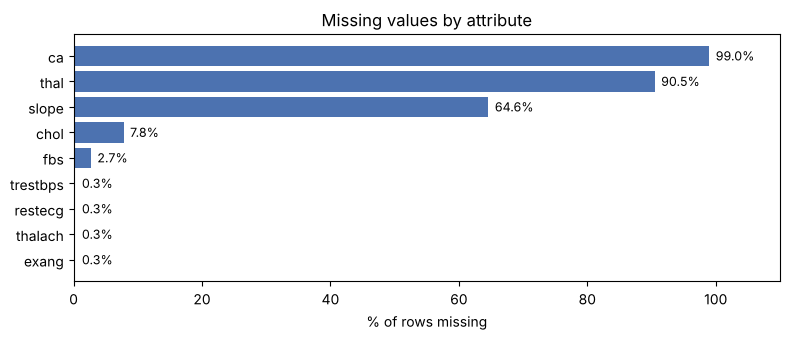

,Missing,% missing
ca,291,99.0
thal,266,90.5
slope,190,64.6
chol,23,7.8
fbs,8,2.7
trestbps,1,0.3
restecg,1,0.3
thalach,1,0.3
exang,1,0.3


In [4]:
missing = pd.DataFrame({"Missing": heart.isna().sum(), "% missing": (heart.isna().mean() * 100).round(1)})
missing = missing[missing["Missing"] > 0].sort_values("Missing", ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(missing.index[::-1], missing["% missing"][::-1], color="#4C72B0")
for i, v in enumerate(missing["% missing"][::-1]):
    ax.text(v + 1, i, f"{v}%", va="center", fontsize=9)
ax.set_xlim(0, 110)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values by attribute")
plt.tight_layout()
plt.show()

print("Exact duplicate rows:", heart.duplicated().sum())
missing

Three attributes are missing for most patients: `ca` (99%), `thal` (90.5%) and `slope` (64.6%). The table below checks whether these gaps are random, by comparing the disease rate among patients with and without each value recorded.

In [5]:
pattern = {}
for col in ["slope", "thal", "chol", "fbs"]:
    recorded = heart[col].notna()
    pattern[col] = {
        "Disease rate when recorded": heart.loc[recorded, "num"].mean(),
        "Disease rate when missing": heart.loc[~recorded, "num"].mean(),
        "Rows missing": (~recorded).sum(),
    }
pattern = pd.DataFrame(pattern).T
pattern["Rows missing"] = pattern["Rows missing"].astype(int)

print("slope recorded vs ST depression (oldpeak > 0):")
print(pd.crosstab(heart["slope"].notna(), heart["oldpeak"] > 0,
                  rownames=["slope recorded"], colnames=["oldpeak > 0"]))
pattern.round(3)

slope recorded vs ST depression (oldpeak > 0):
oldpeak > 0     False  True 
slope recorded              
False             188      2
True                1    103


,Disease rate when recorded,Disease rate when missing,Rows missing
slope,0.702,0.174,190
thal,0.464,0.350,266
chol,0.373,0.217,23
fbs,0.364,0.250,8


**Cleaning decisions:**

- **`ca`, `thal` and `slope` are removed.** With 99%, 90.5% and 64.6% of values missing, they cannot be reliably filled in. Dropping every row with a missing value instead would leave almost no data. The missingness of `slope` is also not random: the crosstab shows it is almost only recorded when the patient had ST depression (`oldpeak` > 0). That information is therefore already captured by `oldpeak`.
- **The single exact duplicate row is removed**, so the same patient record cannot appear in both the training and test sets.
- **The remaining gaps are kept and filled in during modelling.** These are `chol` (7.8%), `fbs` (2.7%) and single values in `trestbps`, `restecg`, `thalach` and `exang`. Removing these rows would discard over 10% of an already small dataset. Instead, they are filled with the **median** (numerical features) or the **most frequent value** (categorical features). The filling is done inside a `Pipeline`, so the values are learnt from the training data only, and no information from the validation or test sets is used.

In [6]:
heart = heart.drop(columns=["ca", "thal", "slope"])
heart = heart.drop_duplicates().reset_index(drop=True)
print(heart.shape)
print(heart["num"].value_counts().rename(index={0: "0 (no disease)", 1: "1 (disease)"}))

(293, 11)
num
0 (no disease)    187
1 (disease)       106
Name: count, dtype: int64


### Split the Dataset

Because the dataset is small, a 60/20/20 split leaves only about 59 patients in each of the validation and test sets. A single misclassified patient changes the accuracy on these sets by about 1.7 percentage points. For this reason, decisions in this notebook (tuning and model selection) are based mainly on **cross-validation on the training set**, which uses every training patient for both fitting and scoring. The validation set provides a second check, and the test set is used once at the end.

In [7]:
target = "num"
X = heart.drop(columns=target)
y = heart[target]

# Split the dataset into 60% Training data, 40% Temporary dataset with a random state of 42
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=42)

# Further Split the temporary dataset into validation data (20%), testing data (20%)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

pd.DataFrame({
    "Rows": [len(y_train), len(y_val), len(y_test)],
    "Disease rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["Training", "Validation", "Testing"]).round(3)

,Rows,Disease rate
Training,175,0.360
Validation,59,0.373
Testing,59,0.356


In [8]:
unique_values = X_train.nunique()
unique_values

age          34
sex           2
cp            4
trestbps     24
chol        110
fbs           2
restecg       3
thalach      59
exang         2
oldpeak       8
dtype: int64

## 2.2 Univariate Analysis

Univariate analysis looks at each attribute on its own: its distribution, central value, spread, skew and outliers. As in the rest of the EDA, only the **training set** is used, so that nothing learnt about the data comes from the validation or test sets.

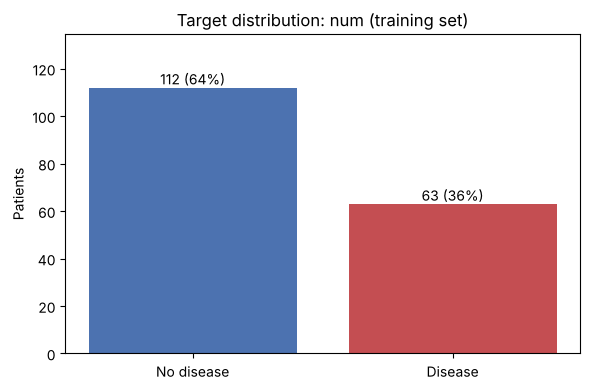

In [9]:
train = X_train.copy()
train["num"] = y_train
labels = {0: "No disease", 1: "Disease"}
colours = {0: "#4C72B0", 1: "#C44E52"}

continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical = ["sex", "cp", "fbs", "restecg", "exang"]

counts = train["num"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([labels[i] for i in counts.index], counts.values, color=[colours[i] for i in counts.index])
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n} ({n / counts.sum():.0%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_ylabel("Patients")
ax.set_title("Target distribution: num (training set)")
plt.tight_layout()
plt.show()

### 2.2.1 Summary Statistics

The table gives the summary statistics for each continuous feature, with two extra columns:

- **skew**: values near 0 mean a symmetrical distribution. Values above +1 or below −1 mean a heavily skewed one.
- **outliers %**: the share of rows that fall outside 1.5 × the interquartile range (IQR) from the quartiles.

In [10]:
summary = train[continuous].describe().T
summary["median"] = train[continuous].median()
summary["skew"] = train[continuous].skew()
q1, q3 = train[continuous].quantile(0.25), train[continuous].quantile(0.75)
iqr = q3 - q1
summary["outliers %"] = ((train[continuous] < q1 - 1.5 * iqr) | (train[continuous] > q3 + 1.5 * iqr)).mean() * 100
summary[["count", "mean", "median", "std", "min", "max", "skew", "outliers %"]].round(2)

,count,mean,median,std,min,max,skew,outliers %
age,175.0,47.44,48.0,7.66,28.0,65.0,-0.24,0.00
trestbps,174.0,132.55,130.0,17.11,92.0,190.0,0.38,0.57
chol,161.0,245.46,230.0,64.80,100.0,518.0,1.25,4.00
thalach,174.0,138.64,140.0,23.45,82.0,190.0,-0.09,0.57
oldpeak,175.0,0.63,0.0,0.93,0.0,4.0,1.28,4.57


### 2.2.2 Distributions and Outliers

Histograms (top) show the shape of each continuous feature, with the median marked by a dashed line. Box plots (bottom) show the spread and any outliers.

oldpeak = 0 (no ST depression): 63.4% of patients


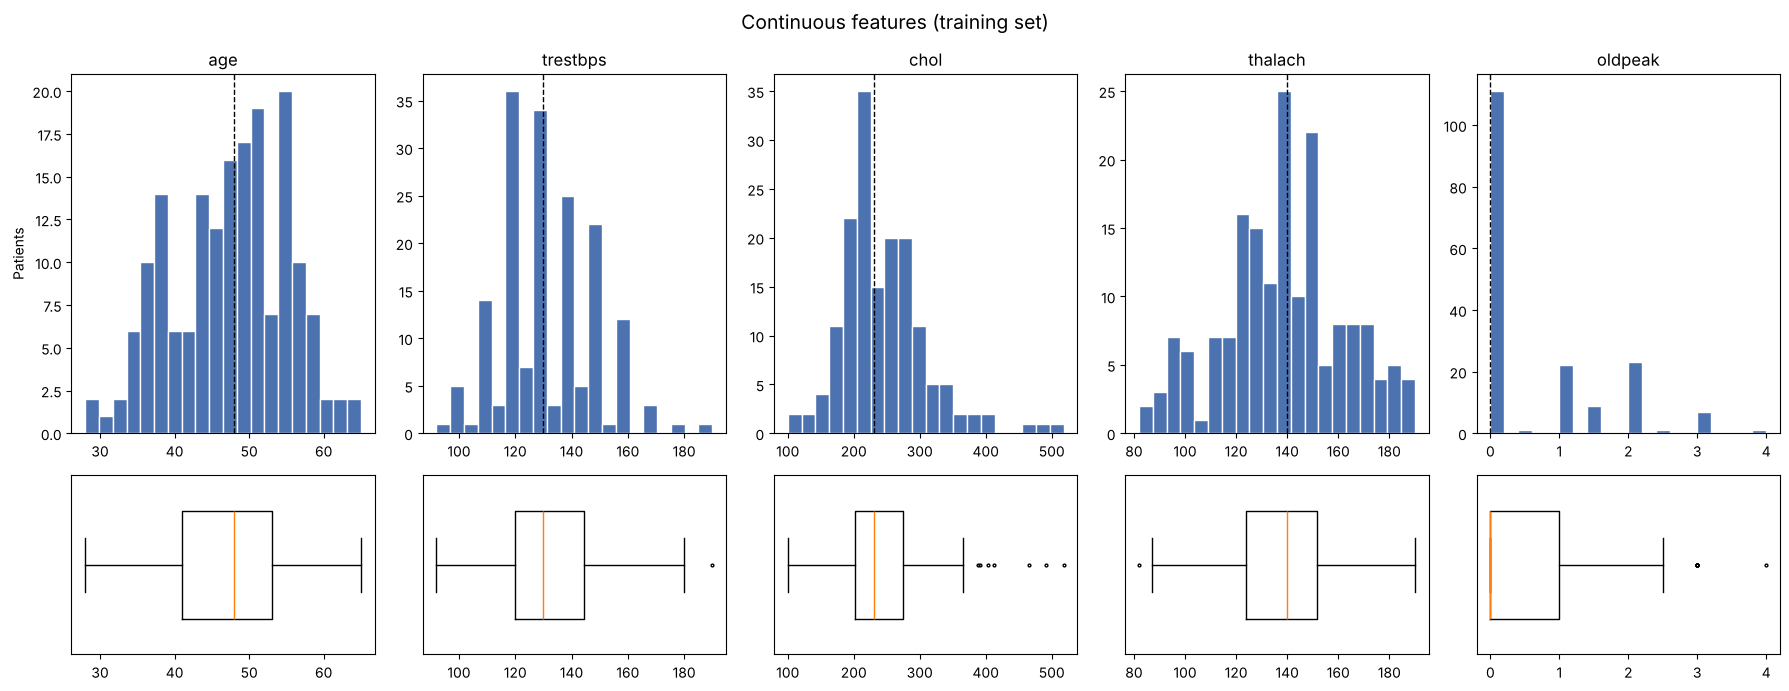

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7), gridspec_kw={"height_ratios": [2, 1]})
for i, col in enumerate(continuous):
    values = train[col].dropna()
    axes[0, i].hist(values, bins=20, color="#4C72B0", edgecolor="white")
    axes[0, i].axvline(values.median(), color="black", linestyle="--", linewidth=1)
    axes[0, i].set_title(col)
    axes[1, i].boxplot(values, vert=False, widths=0.6, flierprops={"marker": ".", "markersize": 4})
    axes[1, i].set_yticks([])
axes[0, 0].set_ylabel("Patients")
plt.suptitle("Continuous features (training set)", fontsize=14)
plt.tight_layout()
plt.show()

print(f"oldpeak = 0 (no ST depression): {(train['oldpeak'] == 0).mean():.1%} of patients")

### 2.2.3 Categorical Features

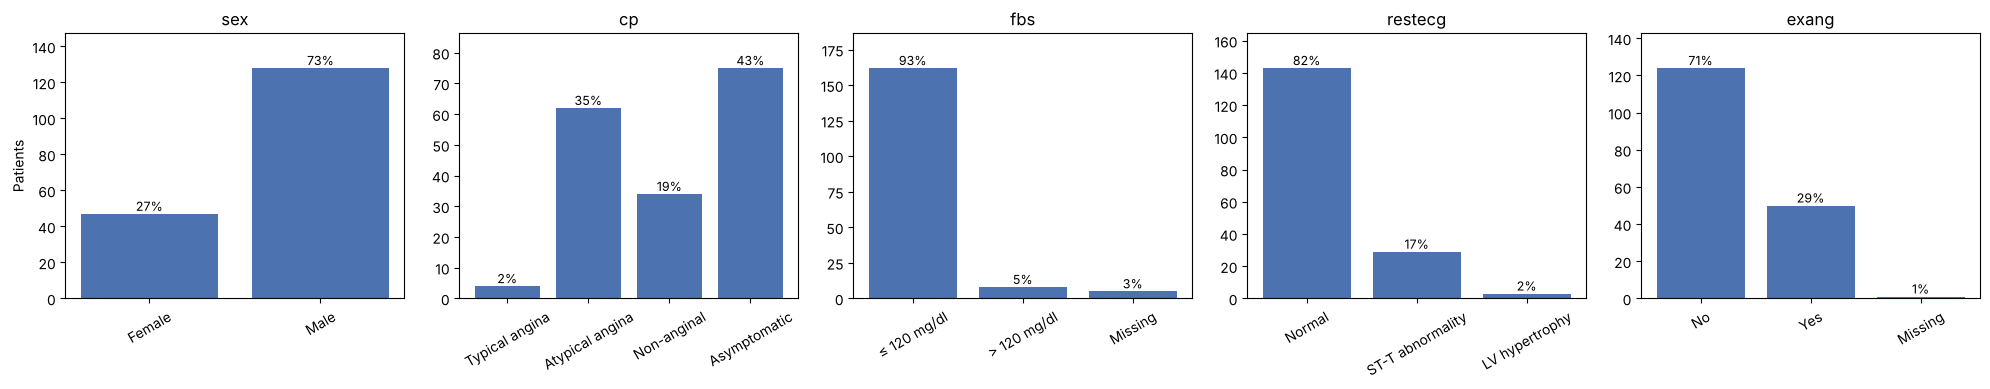

In [12]:
cat_labels = {
    "sex": {0: "Female", 1: "Male"},
    "cp": {1: "Typical angina", 2: "Atypical angina", 3: "Non-anginal", 4: "Asymptomatic"},
    "fbs": {0: "≤ 120 mg/dl", 1: "> 120 mg/dl"},
    "restecg": {0: "Normal", 1: "ST-T abnormality", 2: "LV hypertrophy"},
    "exang": {0: "No", 1: "Yes"},
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, categorical):
    vc = train[col].value_counts(dropna=False).sort_index()
    names = ["Missing" if pd.isna(k) else cat_labels[col][int(k)] for k in vc.index]
    ax.bar(names, vc.values, color="#4C72B0")
    for j, v in enumerate(vc.values):
        ax.text(j, v, f"{v / len(train):.0%}", ha="center", va="bottom", fontsize=9)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(0, vc.max() * 1.15)
axes[0].set_ylabel("Patients")
plt.tight_layout()
plt.show()

### 2.2.4 Univariate Findings

- **Target:** 36% of training patients have heart disease and 64% do not. This imbalance is moderate, but a model that always predicts "no disease" would already be 64% accurate, so balanced accuracy, sensitivity, specificity and ROC AUC are reported alongside accuracy.
- **Continuous features:**
  - `age` (median 48, range 28–65), `trestbps` (median 130 mm Hg) and `thalach` (median 140 bpm) are roughly symmetrical, with almost no outliers.
  - `chol` is moderately right-skewed (skew 1.25), with a long tail up to 518 mg/dl (4% outliers).
  - `oldpeak` is the most skewed (skew 1.28): 63% of patients show no ST depression at all (`oldpeak` = 0), so most of its variation comes from a minority of patients.
  - The outliers are clinically plausible values rather than errors, so they are kept.
- **Categorical features:**
  - The sample is 73% male.
  - Asymptomatic chest pain (43%) and atypical angina (35%) are by far the most common pain types. Typical angina is rare (4 training patients, 2%).
  - 29% of patients had exercise-induced angina.
  - `fbs` and `restecg` are very unbalanced: only 8 patients have high fasting blood sugar, and only 3 show left ventricular hypertrophy. Any conclusions about these small groups will be unreliable.
- **Missing values in the training set:** 14 values of `chol` and 5 of `fbs` are missing, plus one each of `trestbps`, `thalach` and `exang`. These are filled in inside the modelling pipeline (Section 3.1).

## 2.3 Bivariate Analysis

Bivariate analysis looks at attributes two at a time. It has two aims:

1. **Feature vs target:** to find out whether each feature differs between patients with and without heart disease. This tests the research questions.
2. **Feature vs feature:** to find features that are strongly correlated with each other.

### 2.3.1 Continuous Features by Class

Box plots show each continuous feature for the two classes. A **Mann-Whitney U test** checks whether the difference is statistically significant. It compares the two groups without assuming normal distributions, which suits the skewed `oldpeak`. As the effect size, the **rank-biserial correlation (r)** is reported. It ranges from −1 to +1, and roughly, |r| below 0.1 is negligible, 0.1–0.3 small, 0.3–0.5 medium and above 0.5 large. A positive r means values tend to be higher in the disease group.

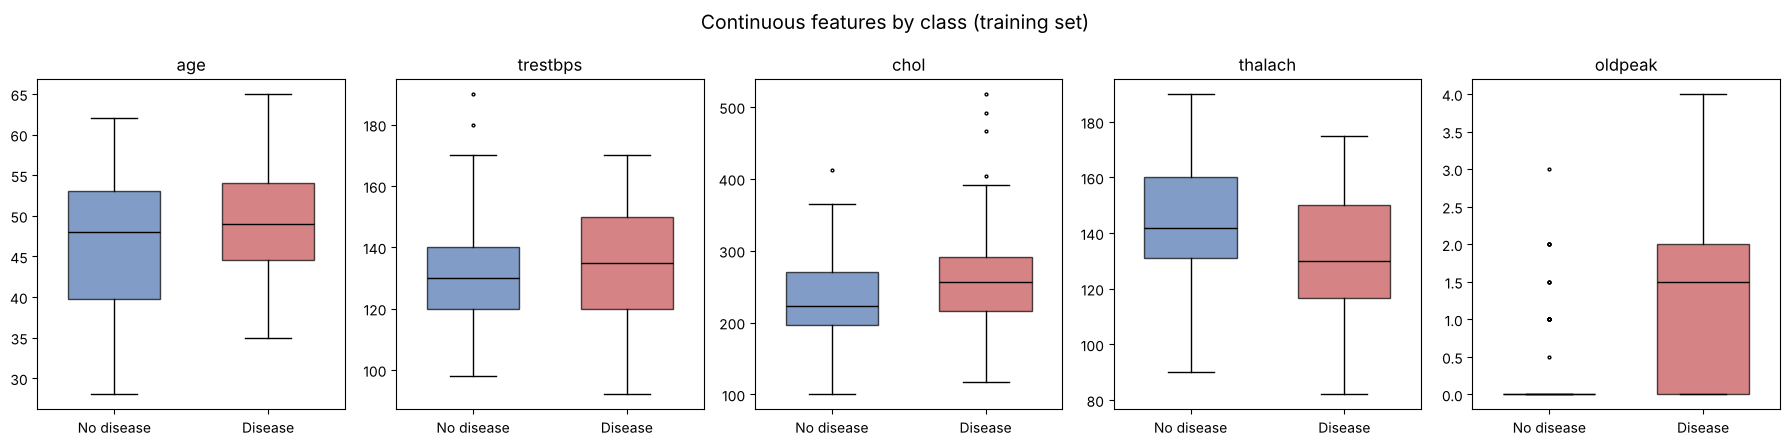

,Median (no disease),Median (disease),U,p-value,Rank-biserial r
oldpeak,0.0,1.5,5554,2.6e-13,+0.574
thalach,142.0,130.0,2226,6.9e-05,-0.363
chol,223.0,256.0,3868,5.5e-03,+0.260
age,48.0,49.0,4192,3.9e-02,+0.188
trestbps,130.0,135.0,4082,6.4e-02,+0.168


In [13]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
for ax, col in zip(axes, continuous):
    data = [train.loc[train["num"] == k, col].dropna() for k in (0, 1)]
    box = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={"color": "black"},
                     flierprops={"marker": ".", "markersize": 4})
    for patch, k in zip(box["boxes"], (0, 1)):
        patch.set_facecolor(colours[k])
        patch.set_alpha(0.7)
    ax.set_xticks([1, 2])
    ax.set_xticklabels([labels[0], labels[1]])
    ax.set_title(col)
plt.suptitle("Continuous features by class (training set)", fontsize=14)
plt.tight_layout()
plt.show()

mw = {}
for col in continuous:
    a = train.loc[train["num"] == 1, col].dropna()
    b = train.loc[train["num"] == 0, col].dropna()
    U, p = mannwhitneyu(a, b, alternative="two-sided")
    mw[col] = {"Median (no disease)": b.median(), "Median (disease)": a.median(),
               "U": U, "p-value": p, "Rank-biserial r": 2 * U / (len(a) * len(b)) - 1}
mw = pd.DataFrame(mw).T.sort_values("Rank-biserial r", key=abs, ascending=False)
mw.style.format({"Median (no disease)": "{:.1f}", "Median (disease)": "{:.1f}", "U": "{:.0f}",
                 "p-value": "{:.1e}", "Rank-biserial r": "{:+.3f}"})

### 2.3.2 Categorical Features by Class

For each categorical feature, the chart shows the disease rate within each category, with the number of patients in brackets. The dashed line marks the overall disease rate. A **chi-square test of independence** is used, with **Cramér's V** as the effect size (0.1 small, 0.3 medium, 0.5 large).

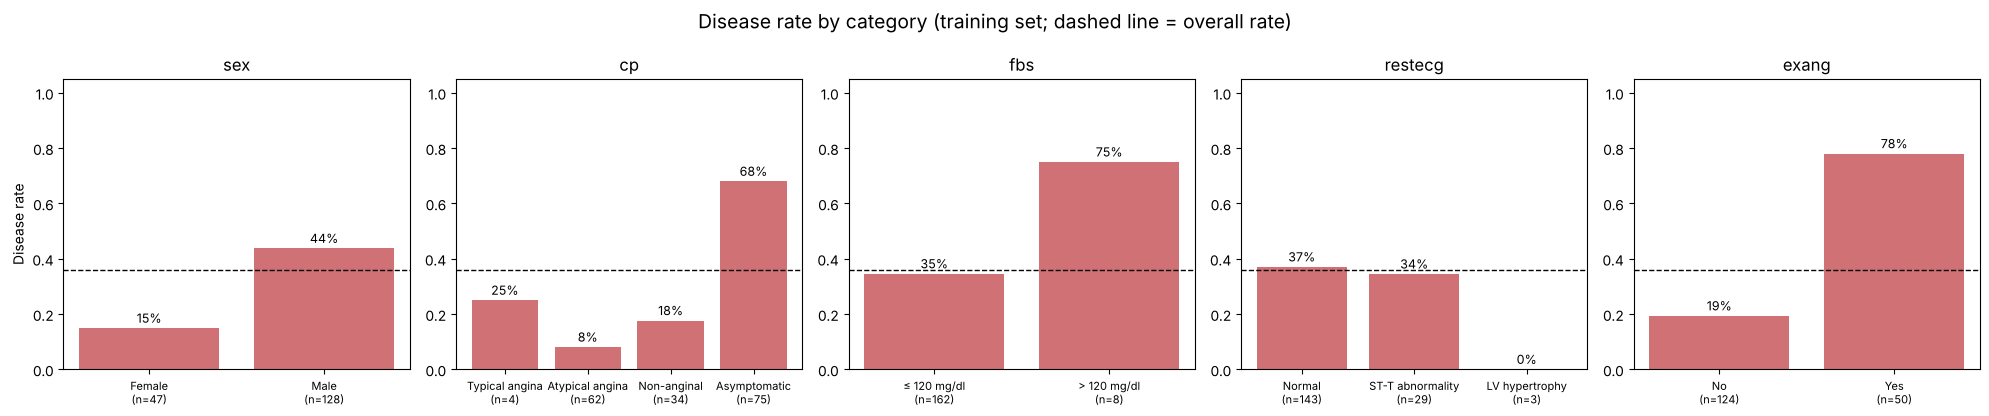

,χ²,p-value,Cramér's V
cp,59.5,7.5e-13,0.583
exang,50.5,1.2e-12,0.539
sex,11.2,8.2e-04,0.253
fbs,3.8,5.2e-02,0.149
restecg,1.8,4.1e-01,0.101


In [14]:
overall = train["num"].mean()
fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))
chi = {}
for ax, col in zip(axes, categorical):
    sub = train[[col, "num"]].dropna()
    rate = sub.groupby(col)["num"].agg(["mean", "size"])
    names = [f"{cat_labels[col][int(k)]}\n(n={n})" for k, n in zip(rate.index, rate["size"])]
    ax.bar(names, rate["mean"], color="#C44E52", alpha=0.8)
    ax.axhline(overall, color="black", linestyle="--", linewidth=1)
    for j, v in enumerate(rate["mean"]):
        ax.text(j, v + 0.02, f"{v:.0%}", ha="center", fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.set_title(col)
    ax.tick_params(axis="x", labelsize=8)
    ct = pd.crosstab(sub[col], sub["num"])
    c2, p, dof, _ = chi2_contingency(ct)
    chi[col] = {"χ²": c2, "p-value": p, "Cramér's V": np.sqrt(c2 / (ct.values.sum() * (min(ct.shape) - 1)))}
axes[0].set_ylabel("Disease rate")
plt.suptitle("Disease rate by category (training set; dashed line = overall rate)", fontsize=14)
plt.tight_layout()
plt.show()

pd.DataFrame(chi).T.sort_values("Cramér's V", ascending=False).style.format(
    {"χ²": "{:.1f}", "p-value": "{:.1e}", "Cramér's V": "{:.3f}"})

### 2.3.3 Correlation Between Features

Spearman correlation is used rather than Pearson, because it is based on ranks and is not distorted by skew or outliers. `num` is included so that each feature's correlation with the target can be seen alongside the correlations between features.

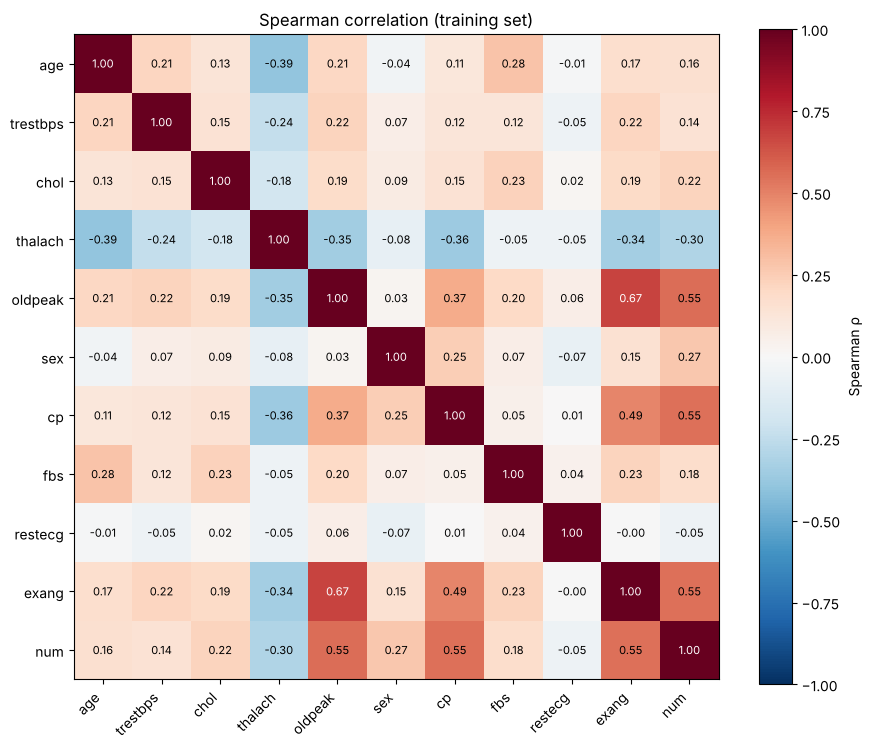

,ρ with num
oldpeak,0.555
exang,0.552
cp,0.550
thalach,-0.303
sex,0.266
chol,0.219
fbs,0.178
age,0.157
trestbps,0.141
restecg,-0.052


In [15]:
corr_cols = continuous + ["sex", "cp", "fbs", "restecg", "exang", "num"]
corr = train[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)))
ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Spearman ρ")
ax.set_title("Spearman correlation (training set)")
plt.tight_layout()
plt.show()

corr["num"].drop("num").sort_values(key=abs, ascending=False).rename("ρ with num").round(3).to_frame()

### 2.3.4 Bivariate Findings and Research Questions

| ID | Result | Evidence (training set) |
|---|---|---|
| RQ1 | **Supported** | Asymptomatic patients have a disease rate of 68%, against 8–25% for the other pain types. `cp` has the strongest association of any feature (Cramér's V = 0.58, large). |
| RQ2 | **Supported** | 78% of patients with exercise-induced angina have heart disease, against 19% without it (Cramér's V = 0.54, large). |
| RQ3 | **Supported** | The median ST depression is 1.5 mm in the disease group and 0 in the healthy group. This is the largest effect of any continuous feature (rank-biserial r = +0.57, large). |
| RQ4 | **Supported** | The median maximum heart rate is 130 bpm with disease, against 142 without (r = −0.36, medium). |
| RQ5 | **Supported** | Men have a disease rate of 44%, against 15% for women (Cramér's V = 0.25, small to medium). |
| RQ6 | **Supported** | The resting risk factors separate the classes much less clearly than the exercise test. Cholesterol is somewhat higher with disease (256 vs 223 mg/dl, r = +0.26, small). The difference in resting blood pressure is not statistically significant (p = 0.06). High fasting blood sugar is linked to disease (75%), but in only 8 patients (p = 0.05). The resting ECG shows no relationship (V = 0.10, p = 0.41). |

**Other findings:**

- **Age** has only a small effect (median 49 vs 48 years, r = +0.19). This is probably because the sample is fairly young (median 48), so most patients fall within a narrow age range.
- **The three strongest features are linked to each other.** Exercise-induced angina and ST depression are fairly strongly correlated (ρ = 0.67), and chest pain type correlates with both (ρ = 0.49 with `exang`, 0.37 with `oldpeak`). They partly measure the same thing: how the heart responds under stress. Multivariate analysis is needed to see whether each one adds information beyond the others.
- **Maximum heart rate falls with age** (ρ = −0.39), as expected physiologically. This needs to be considered when interpreting RQ4: part of the lower heart rate in the disease group could reflect age rather than disease.
- No pair of features is so strongly correlated (|ρ| > 0.8) that one would be redundant.

## 2.4 Multivariate Analysis

Multivariate analysis looks at three or more attributes together, to find out:

1. whether features combine to separate the classes better than any one feature alone;
2. whether a relationship still holds once other features are accounted for (for example, whether the sex difference in RQ5 is explained by men reporting different chest pain);
3. how well the classes separate when all features are considered together (PCA);
4. how much the features overlap with each other (VIF).

### 2.4.1 Feature Combinations by Class

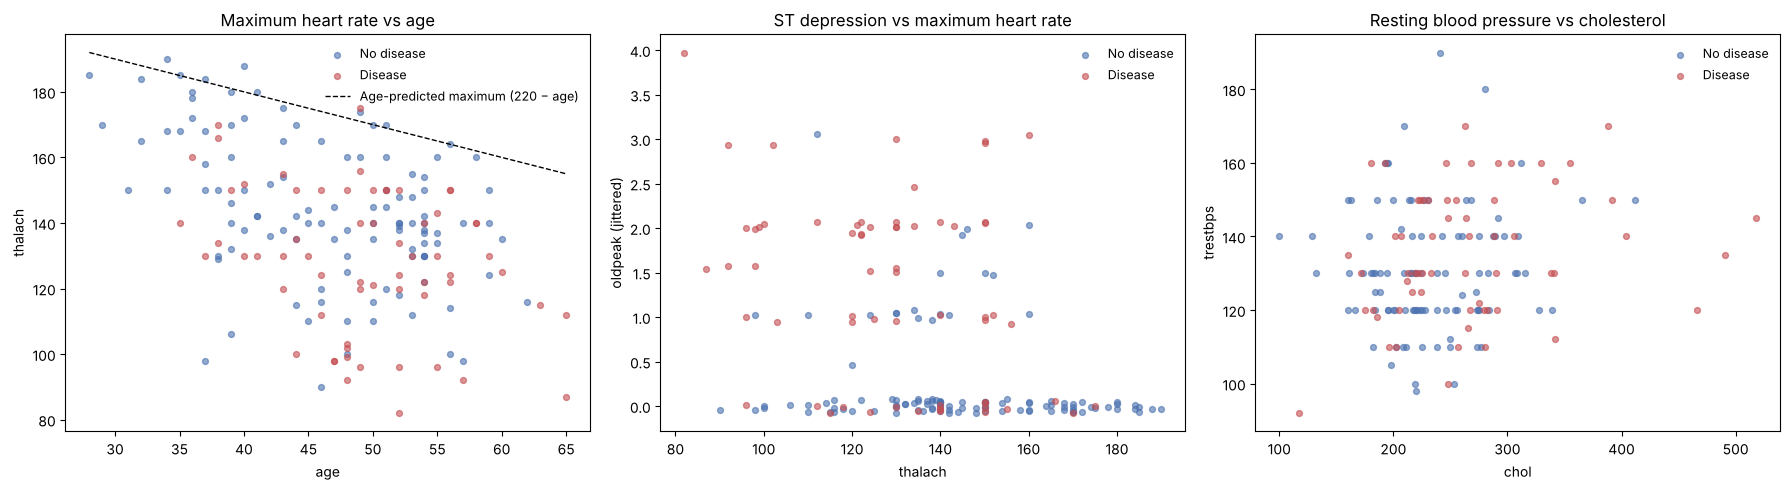

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
jitter = np.random.default_rng(42)
for k in (0, 1):
    sub = train[train["num"] == k]
    axes[0].scatter(sub["age"], sub["thalach"], s=18, alpha=0.6, color=colours[k], label=labels[k])
    axes[1].scatter(sub["thalach"], sub["oldpeak"] + jitter.uniform(-0.08, 0.08, len(sub)),
                    s=18, alpha=0.6, color=colours[k], label=labels[k])
    axes[2].scatter(sub["chol"], sub["trestbps"], s=18, alpha=0.6, color=colours[k], label=labels[k])

ages = np.linspace(train["age"].min(), train["age"].max(), 10)
axes[0].plot(ages, 220 - ages, color="black", linestyle="--", linewidth=1, label="Age-predicted maximum (220 − age)")
axes[0].set_xlabel("age")
axes[0].set_ylabel("thalach")
axes[0].set_title("Maximum heart rate vs age")
axes[1].set_xlabel("thalach")
axes[1].set_ylabel("oldpeak (jittered)")
axes[1].set_title("ST depression vs maximum heart rate")
axes[2].set_xlabel("chol")
axes[2].set_ylabel("trestbps")
axes[2].set_title("Resting blood pressure vs cholesterol")
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

### 2.4.2 Interaction Between the Strongest Categorical Features

The table shows the disease rate for every combination of chest pain type, exercise-induced angina and sex, with the number of patients in each group. Groups with fewer than about 10 patients should be read with caution.

In [17]:
combo = train.dropna(subset=["exang"]).assign(
    chest_pain=lambda d: np.where(d["cp"] == 4, "Asymptomatic", "Other pain type"),
    angina=lambda d: d["exang"].map({0: "No exercise angina", 1: "Exercise angina"}),
    sex_label=lambda d: d["sex"].map(cat_labels["sex"]),
)
table = combo.groupby(["chest_pain", "angina", "sex_label"])["num"].agg(["mean", "size"])
table.columns = ["Disease rate", "Patients"]
table.style.format({"Disease rate": "{:.0%}"}).background_gradient(subset=["Disease rate"], cmap="Reds", vmin=0, vmax=1)

Disease rate  Patients
chest_pain      angina             sex_label                        
Asymptomatic    Exercise angina    Female         0.500000         6
                                   Male           0.916667        36
                No exercise angina Female         0.200000         5
                                   Male           0.500000        28
Other pain type Exercise angina    Female         0.500000         2
                                   Male           0.333333         6
                No exercise angina Female         0.060606        33
                                   Male           0.120690        58

To test RQ5 more carefully, the sex difference in disease rate is compared within each chest pain group. If the difference disappears within groups, the overall sex effect is explained by chest pain type. If it remains, sex carries information of its own.

In [18]:
sex_check = train.groupby([np.where(train["cp"] == 4, "Asymptomatic", "Other pain type"), "sex"])["num"].agg(["mean", "size"]).unstack()
sex_check.columns = [f"{'Disease rate' if a == 'mean' else 'Patients'} ({cat_labels['sex'][b]})" for a, b in sex_check.columns]
sex_check.loc["All patients"] = [train.loc[train["sex"] == 0, "num"].mean(), train.loc[train["sex"] == 1, "num"].mean(),
                                 (train["sex"] == 0).sum(), (train["sex"] == 1).sum()]
sex_check.style.format({c: "{:.0%}" for c in sex_check.columns if c.startswith("Disease")} |
                       {c: "{:.0f}" for c in sex_check.columns if c.startswith("Patients")})

,Disease rate (Female),Disease rate (Male),Patients (Female),Patients (Male)
Asymptomatic,36%,73%,11,64
Other pain type,8%,14%,36,64
All patients,15%,44%,47,128


### 2.4.3 Principal Component Analysis (PCA)

PCA combines the features into new uncorrelated axes, ordered by how much of the variation in the data they capture. Plotting the first two components shows how far the classes separate when all features are considered together. For this step only, missing values are filled with the training-set median, `cp` and `restecg` are one-hot encoded, and all features are standardised, so that features with large numbers (such as `chol`) do not dominate.

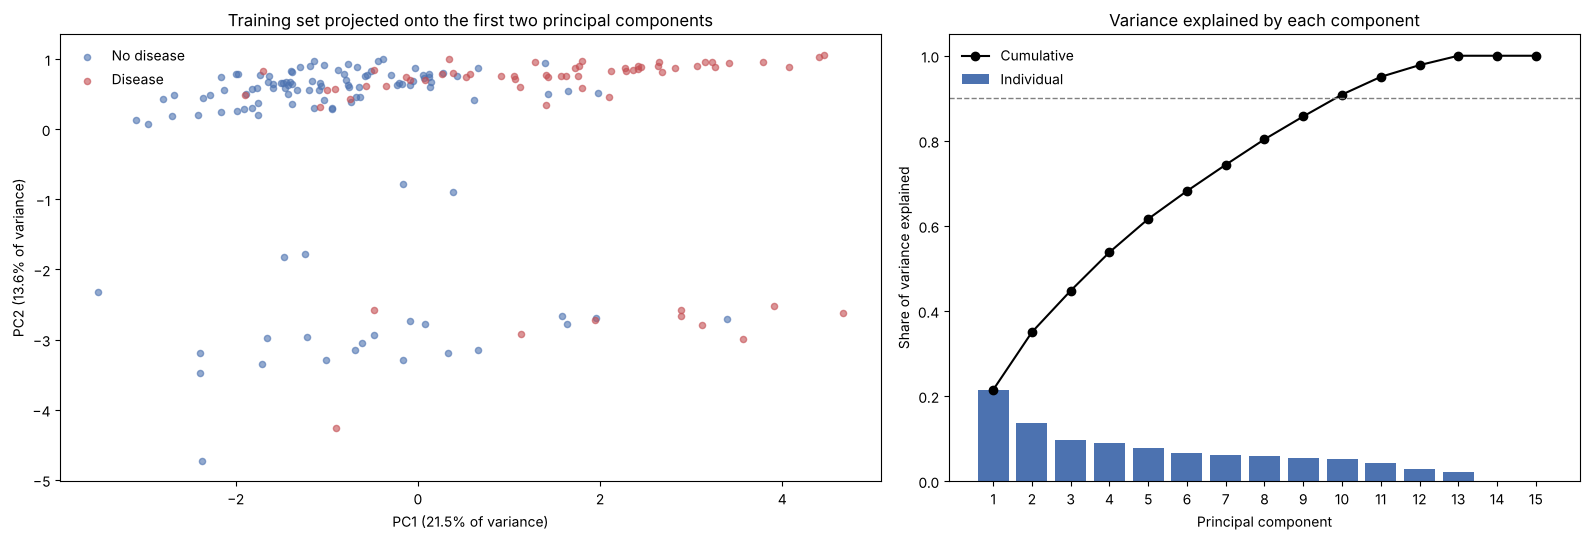

,PC1,PC2
exang,0.43,0.06
cp_4,0.43,0.02
oldpeak,0.40,-0.03
thalach,-0.37,-0.02
cp_2,-0.30,-0.02
age,0.25,0.07
trestbps,0.21,0.04
chol,0.20,0.01
fbs,0.18,-0.01
cp_3,-0.16,0.07


In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_X = pd.get_dummies(X_train.fillna(X_train.median()), columns=["cp", "restecg"], dtype=int)
Z = StandardScaler().fit_transform(pca_X)
pca = PCA().fit(Z)
pcs = pca.transform(Z)
explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
for k in (0, 1):
    m = (y_train == k).values
    axes[0].scatter(pcs[m, 0], pcs[m, 1], s=20, alpha=0.6, color=colours[k], label=labels[k])
axes[0].set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
axes[0].set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
axes[0].set_title("Training set projected onto the first two principal components")
axes[0].legend(frameon=False)
steps = np.arange(1, len(explained) + 1)
axes[1].bar(steps, explained, color="#4C72B0", label="Individual")
axes[1].plot(steps, np.cumsum(explained), color="black", marker="o", label="Cumulative")
axes[1].axhline(0.9, color="grey", linestyle="--", linewidth=1)
axes[1].set_xticks(steps)
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Share of variance explained")
axes[1].set_title("Variance explained by each component")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

pd.DataFrame(pca.components_[:2].T, index=pca_X.columns, columns=["PC1", "PC2"]).round(2).sort_values("PC1", key=abs, ascending=False)

### 2.4.4 Multicollinearity (Variance Inflation Factor)

The variance inflation factor (VIF) measures how well each feature can be predicted from all of the other features combined. VIF above 10 (or, more cautiously, above 5) indicates strong multicollinearity. One dummy column of each one-hot-encoded feature is dropped (the reference category), as including all of them would make VIF undefined. The most common category is used as the reference: asymptomatic chest pain and a normal ECG. Using a rare category, such as typical angina (only 6% of patients), would inflate the VIF of the remaining dummy columns artificially.

In [20]:
# the most common category of each feature is used as the reference: asymptomatic chest pain (cp = 4) and normal ECG
vif_X = pd.get_dummies(X_train.fillna(X_train.median()), columns=["cp", "restecg"], dtype=int).drop(columns=["cp_4", "restecg_0.0"])
vif_corr = vif_X.corr().values
vif = pd.Series(np.diag(np.linalg.inv(vif_corr)), index=vif_X.columns).sort_values(ascending=False)
vif.rename("VIF").round(2).to_frame()

,VIF
exang,2.08
oldpeak,1.81
cp_2,1.73
thalach,1.58
cp_3,1.58
age,1.46
fbs,1.21
cp_1,1.14
sex,1.13
trestbps,1.13


### 2.4.5 Multivariate Findings

- **Features combine strongly.** Male asymptomatic patients with exercise-induced angina have a disease rate of 92% (36 patients). Patients of either sex with another pain type and no exercise angina have only 6–12% (91 patients). Chest pain type and exercise angina together sort most patients into a clearly high-risk or clearly low-risk group, which a model should be able to exploit.
- **RQ5 holds once chest pain is accounted for.** Within each chest pain group, men still have a much higher disease rate than women: 73% vs 36% among asymptomatic patients, and 14% vs 8% among the rest. Women are also less often asymptomatic (11 of 47, against 64 of 128 men). This explains part of the overall gap, but not all of it, so sex carries some information of its own.
- **RQ4 needs care.** In the heart rate vs age scatter plot, diseased patients tend to sit lower for their age, further below the age-predicted maximum (220 − age). The median patient with disease reaches 74% of their predicted maximum, against 83% without disease. The lower maximum heart rate is therefore not just an effect of age, which supports RQ4 and motivates the engineered feature in Section 4.2.
- **ST depression and maximum heart rate together** separate the classes well. Of the patients with `oldpeak` ≥ 1.5, 81% have heart disease, across the whole range of heart rates. Of those with no ST depression and a maximum heart rate of at least 140 bpm, only 17% do. Cholesterol and resting blood pressure, plotted together, show no visible separation, which agrees with RQ6.
- **The classes separate reasonably well when all features are considered together.** PC1 explains 21.5% of the variance and is driven by `exang`, asymptomatic chest pain, `oldpeak` and (negatively) `thalach`. Along PC1 the two classes are largely separated, unlike in more difficult problems. PC2 (13.6%) is dominated by the resting ECG and does not separate the classes. Ten components are needed to reach 90% of the variance, and the last two explain nothing because the one-hot columns of each feature always sum to one.
- **Multicollinearity is low.** With the most common categories as references, every VIF is below 2.1. The highest are `exang` (2.08) and `oldpeak` (1.81), reflecting their correlation, but no feature needs to be removed for this reason.

# 3 Classification

With the data cleaned and split, classification models can now be trained to predict `num`. The approach follows the same steps as before, adapted for a small, binary, medical dataset:

1. Build a preprocessing pipeline that fills in missing values, encodes the categorical features and scales the numerical ones.
2. Train a baseline and three initial models (Gaussian Naive Bayes, Decision Tree, Random Forest).
3. Tune the Random Forest.
4. Train and tune four further algorithms: Logistic Regression, K-Nearest Neighbours, Support Vector Machine and Gradient Boosting.
5. Select the best tuned model and evaluate it once on the held-out test set.

**Choice of metric.** Models are tuned and compared on **ROC AUC**, the area under the ROC curve. It measures how well the model ranks patients with disease above patients without, across every possible decision threshold. 0.5 is random guessing and 1.0 is perfect. With only 35 patients per cross-validation fold, ROC AUC is more stable than metrics that depend on a single threshold, such as accuracy or F1. It is also unaffected by class imbalance, and it leaves the choice of threshold free to be set later for screening (Section 4.2.2). Accuracy, balanced accuracy, sensitivity, specificity and macro F1 are also reported.

**Cross-validation.** Because the folds are small, **repeated** stratified 5-fold cross-validation is used. The 5-fold split is repeated 5 times with different shuffles, giving 25 scores per model, which makes the averages much more reliable than a single 5-fold run.

## 3.1 Feature Preparation

All preprocessing is placed inside a scikit-learn `Pipeline` together with the model, so it is re-fitted on the training part of every cross-validation fold, and nothing is learnt from the data being scored:

- **Numerical features** (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`): missing values are filled with the training median, then standardised to mean 0 and standard deviation 1. Scaling is needed for Logistic Regression, KNN and SVM, and makes no difference to the tree-based models.
- **Binary features** (`sex`, `fbs`, `exang`): missing values are filled with the most frequent value.
- **Nominal features** (`cp`, `restecg`): missing values are filled with the most frequent value, then one-hot encoded, as their codes have no meaningful order.

In [21]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.base import clone

numeric = ["age", "trestbps", "chol", "thalach", "oldpeak"]
binary = ["sex", "fbs", "exang"]
nominal = ["cp", "restecg"]

def make_preprocess(columns, extra_numeric=()):
    """Preprocessing for whichever of the known features are present in `columns`."""
    num = [c for c in numeric + list(extra_numeric) if c in columns]
    steps = [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
             ("bin", SimpleImputer(strategy="most_frequent"), [c for c in binary if c in columns]),
             ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")),
              [c for c in nominal if c in columns])]
    return ColumnTransformer([s for s in steps if s[2]])

def make_model(clf, columns=X_train.columns, extra_numeric=()):
    return Pipeline([("prep", make_preprocess(columns, extra_numeric)), ("clf", clf)])

def evaluate(model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = model.predict(X)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Balanced accuracy": balanced_accuracy_score(y, pred),
        "Sensitivity": recall_score(y, pred, pos_label=1),
        "Specificity": recall_score(y, pred, pos_label=0),
        "Macro F1": f1_score(y, pred, average="macro"),
        "ROC AUC": roc_auc_score(y, proba),
    }

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

prep_check = make_preprocess(X_train.columns).fit(X_train)
print("Features after preprocessing:", prep_check.get_feature_names_out().size)
print(list(prep_check.get_feature_names_out()))

Features after preprocessing: 15
['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'bin__sex', 'bin__fbs', 'bin__exang', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__cp_4.0', 'cat__restecg_0.0', 'cat__restecg_1.0', 'cat__restecg_2.0']


## 3.2 Baseline and Initial Models

A `DummyClassifier` that always predicts the most common class (no disease) is used as a baseline; any useful model must clearly beat it. Three models are then compared:

- **Gaussian Naive Bayes**: a simple probabilistic model that assumes features are independent and normally distributed.
- **Decision Tree**: learns a set of if/then rules. It is easy to interpret, but on a small dataset it tends to over-fit.
- **Random Forest**: an ensemble of many decision trees, each trained on a random sample of rows and features, which reduces over-fitting.

Each model is scored with repeated 5-fold cross-validation on the training set (mean and standard deviation of ROC AUC over 25 folds), and once on the validation set.

In [22]:
models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}

results, cv_auc, cv_std = {}, {}, {}
for name, clf in models.items():
    model = make_model(clf)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_auc[name], cv_std[name] = scores.mean(), scores.std()
    results[name] = evaluate(model.fit(X_train, y_train), X_val, y_val)

val_results = pd.DataFrame(results).T
val_results.insert(0, "CV ROC AUC (train)", pd.Series(cv_auc))
val_results.insert(1, "CV std", pd.Series(cv_std))
val_results.round(3)

,CV ROC AUC (train),CV std,Accuracy,Balanced accuracy,Sensitivity,Specificity,Macro F1,ROC AUC
Baseline (most frequent),0.500,0.000,0.627,0.500,0.000,1.000,0.385,0.500
Gaussian Naive Bayes,0.862,0.056,0.729,0.765,0.909,0.622,0.728,0.850
Decision Tree,0.684,0.055,0.847,0.823,0.727,0.919,0.832,0.823
Random Forest,0.862,0.045,0.847,0.832,0.773,0.892,0.835,0.920


## 3.3 Hyperparameter Tuning

The Random Forest is tuned with `RandomizedSearchCV`, using the repeated 5-fold cross-validation on the training set only, so the validation and test sets stay unseen. Settings that limit tree size (`max_depth`, `min_samples_leaf`) are included, as they help prevent over-fitting on a small dataset.

In [23]:
param_dist = {
    "clf__n_estimators": [100, 300, 500],
    "clf__max_depth": [None, 3, 5, 8],
    "clf__min_samples_leaf": [1, 3, 5, 10],
    "clf__max_features": ["sqrt", "log2", 0.5],
    "clf__class_weight": [None, "balanced"],
}
search = RandomizedSearchCV(make_model(RandomForestClassifier(random_state=42)), param_distributions=param_dist,
                            n_iter=20, scoring="roc_auc", cv=cv, random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

print("Best parameters:", {k.replace("clf__", ""): v for k, v in search.best_params_.items()})
best_i = search.best_index_
print(f"Best cross-validated ROC AUC: {search.best_score_:.3f} ± {search.cv_results_['std_test_score'][best_i]:.3f}")

best_rf = search.best_estimator_
tuned = {"Random Forest (tuned)": best_rf}
val_results.loc["Random Forest (tuned)"] = [search.best_score_, search.cv_results_["std_test_score"][best_i],
                                             *evaluate(best_rf, X_val, y_val).values()]
val_results.round(3)

Best parameters: {'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 3, 'class_weight': None}
Best cross-validated ROC AUC: 0.893 ± 0.043


,CV ROC AUC (train),CV std,Accuracy,Balanced accuracy,Sensitivity,Specificity,Macro F1,ROC AUC
Baseline (most frequent),0.500,0.000,0.627,0.500,0.000,1.000,0.385,0.500
Gaussian Naive Bayes,0.862,0.056,0.729,0.765,0.909,0.622,0.728,0.850
Decision Tree,0.684,0.055,0.847,0.823,0.727,0.919,0.832,0.823
Random Forest,0.862,0.045,0.847,0.832,0.773,0.892,0.835,0.920
Random Forest (tuned),0.893,0.043,0.780,0.741,0.591,0.892,0.751,0.899


## 3.4 Further Classification Algorithms

Four more algorithms are trained and compared:

- **Logistic Regression:** a linear model that estimates the probability of disease from a weighted sum of the features. Its coefficients are easy to interpret, which is valuable in a medical setting, but it can only draw a straight-line boundary.
- **K-Nearest Neighbours (KNN):** classifies each patient by a majority vote of the *k* most similar patients in the training set. It relies entirely on distances, so the scaling step in the pipeline is essential.
- **Support Vector Machine (SVM):** finds the boundary that separates the classes with the widest possible margin. With an RBF kernel it can learn curved boundaries. `probability=True` is set so that it outputs probabilities, which are needed for ROC curves and for the ensemble in Section 4.
- **Gradient Boosting:** builds shallow decision trees one after another, with each tree correcting the errors of the previous ones. On a dataset of this size, scikit-learn's standard `GradientBoostingClassifier` trains quickly. `subsample` < 1 trains each tree on a random subset of rows, which reduces over-fitting.

Each model is tuned with `GridSearchCV`, using the same repeated cross-validation and ROC AUC scoring.

In [24]:
candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000),
        {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]},
    ),
    "K-Nearest Neighbours": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [3, 5, 9, 15, 21, 31], "clf__weights": ["uniform", "distance"]},
    ),
    "Support Vector Machine": (
        SVC(probability=True, random_state=42),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.1], "clf__class_weight": [None, "balanced"]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {"clf__n_estimators": [50, 100, 200], "clf__learning_rate": [0.05, 0.1],
         "clf__max_depth": [2, 3], "clf__subsample": [0.8, 1.0]},
    ),
}

for name, (clf, grid) in candidates.items():
    gs = GridSearchCV(make_model(clf), grid, scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    sd = gs.cv_results_["std_test_score"][gs.best_index_]
    val_results.loc[name] = [gs.best_score_, sd, *evaluate(gs.best_estimator_, X_val, y_val).values()]
    print(f"{name:24s} CV ROC AUC = {gs.best_score_:.3f} ± {sd:.3f}   best params: "
          f"{ {k.replace('clf__', ''): v for k, v in gs.best_params_.items()} }")

Logistic Regression      CV ROC AUC = 0.892 ± 0.042   best params: {'C': 1, 'class_weight': None}
K-Nearest Neighbours     CV ROC AUC = 0.874 ± 0.055   best params: {'n_neighbors': 31, 'weights': 'distance'}
Support Vector Machine   CV ROC AUC = 0.896 ± 0.046   best params: {'C': 1, 'class_weight': 'balanced', 'gamma': 0.01}
Gradient Boosting        CV ROC AUC = 0.866 ± 0.042   best params: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 50, 'subsample': 0.8}


### 3.4.1 Model Comparison

The chart compares every model's cross-validated ROC AUC on the training set (bars, with error bars showing ± one standard deviation across the 25 folds) and its ROC AUC on the validation set (dots). The table lists all metrics. Accuracy, sensitivity and specificity use the default threshold of 0.5.

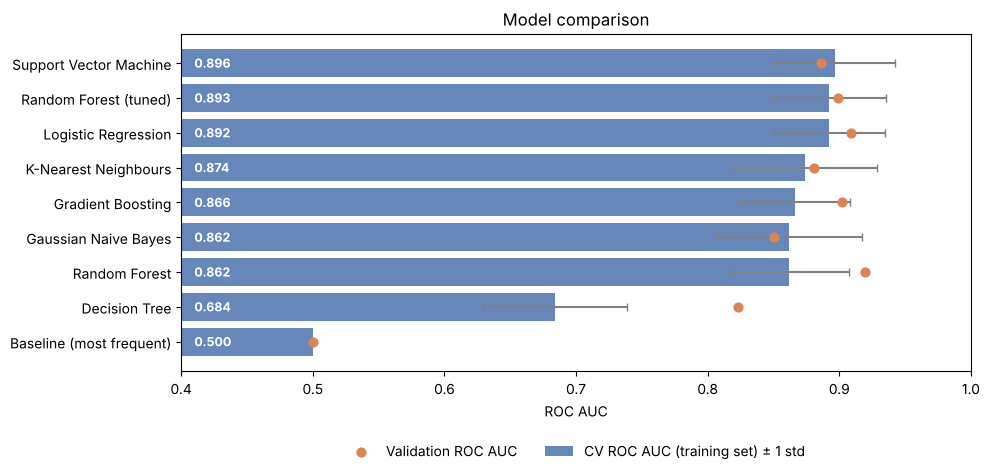

,CV ROC AUC (train),CV std,Accuracy,Balanced accuracy,Sensitivity,Specificity,Macro F1,ROC AUC
Support Vector Machine,0.896,0.046,0.814,0.805,0.773,0.838,0.802,0.886
Random Forest (tuned),0.893,0.043,0.780,0.741,0.591,0.892,0.751,0.899
Logistic Regression,0.892,0.042,0.814,0.805,0.773,0.838,0.802,0.909
K-Nearest Neighbours,0.874,0.055,0.746,0.696,0.500,0.892,0.705,0.881
Gradient Boosting,0.866,0.042,0.847,0.823,0.727,0.919,0.832,0.902
Gaussian Naive Bayes,0.862,0.056,0.729,0.765,0.909,0.622,0.728,0.850
Random Forest,0.862,0.045,0.847,0.832,0.773,0.892,0.835,0.920
Decision Tree,0.684,0.055,0.847,0.823,0.727,0.919,0.832,0.823
Baseline (most frequent),0.500,0.000,0.627,0.500,0.000,1.000,0.385,0.500


In [25]:
comparison = val_results.sort_values("CV ROC AUC (train)", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = comparison.iloc[::-1]
y_pos = np.arange(len(plot_df))
ax.barh(y_pos, plot_df["CV ROC AUC (train)"], xerr=plot_df["CV std"], color="#4C72B0", alpha=0.85,
        ecolor="grey", capsize=3, label="CV ROC AUC (training set) ± 1 std")
ax.scatter(plot_df["ROC AUC"], y_pos, color="#DD8452", zorder=3, s=40, label="Validation ROC AUC")
for yp, v in zip(y_pos, plot_df["CV ROC AUC (train)"]):
    ax.text(0.41, yp, f"{v:.3f}", va="center", color="white", fontsize=9, fontweight="bold")
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index)
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("ROC AUC")
ax.set_title("Model comparison")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

comparison.style.format("{:.3f}").highlight_max(subset=["CV ROC AUC (train)", "ROC AUC", "Balanced accuracy"], color="#D9EAD3")

## 3.5 Final Evaluation on the Test Set

The tuned model with the highest **cross-validated** ROC AUC is selected. Cross-validation is used for this choice rather than the validation set, because with only 59 patients the validation scores move noticeably with every patient. The selected model is retrained on the training and validation sets combined (234 patients), and then evaluated once on the test set, which has not been used at any earlier stage.

In [26]:
best_name = comparison.loc[list(tuned), "CV ROC AUC (train)"].idxmax()
print("Selected model:", best_name)
print()

X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

final_model = clone(tuned[best_name]).fit(X_trainval, y_trainval)
y_pred = final_model.predict(X_test)
final_scores = evaluate(final_model, X_test, y_test)

print(pd.Series(final_scores).round(3).to_string())
print()
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"], digits=3))

Selected model: Support Vector Machine

Accuracy             0.797
Balanced accuracy    0.778
Sensitivity          0.714
Specificity          0.842
Macro F1             0.778
ROC AUC              0.902

              precision    recall  f1-score   support

  No disease      0.842     0.842     0.842        38
     Disease      0.714     0.714     0.714        21

    accuracy                          0.797        59
   macro avg      0.778     0.778     0.778        59
weighted avg      0.797     0.797     0.797        59



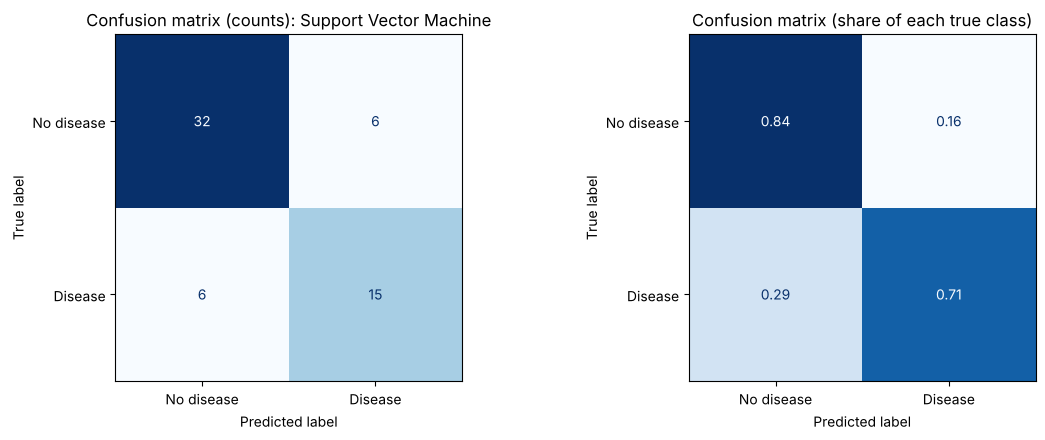

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No disease", "Disease"],
                                        ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix (counts): {best_name}")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No disease", "Disease"], normalize="true",
                                        values_format=".2f", ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Confusion matrix (share of each true class)")
plt.tight_layout()
plt.show()

### 3.5.1 Test-Set Scores for All Tuned Models (for information only)

The model was selected by cross-validation alone, and that choice is not changed here. For transparency, every tuned model is also retrained on training + validation data and scored on the test set. With 59 test patients, differences of a few hundredths should not be over-interpreted.

In [28]:
test_scores = {name: evaluate(clone(m).fit(X_trainval, y_trainval), X_test, y_test) for name, m in tuned.items()}
test_table = pd.DataFrame(test_scores).T
test_table.insert(0, "CV ROC AUC (train)", comparison.loc[list(tuned), "CV ROC AUC (train)"])
test_table.sort_values("CV ROC AUC (train)", ascending=False).round(3)

,CV ROC AUC (train),Accuracy,Balanced accuracy,Sensitivity,Specificity,Macro F1,ROC AUC
Support Vector Machine,0.896,0.797,0.778,0.714,0.842,0.778,0.902
Random Forest (tuned),0.893,0.831,0.794,0.667,0.921,0.806,0.897
Logistic Regression,0.892,0.814,0.791,0.714,0.868,0.794,0.896
K-Nearest Neighbours,0.874,0.780,0.733,0.571,0.895,0.744,0.890
Gradient Boosting,0.866,0.780,0.744,0.619,0.868,0.751,0.888


## 3.6 Feature Importance

**Permutation importance** is used, which works for any model. Each original feature in the test set is shuffled in turn, and the drop in ROC AUC is measured. Because the shuffling happens before the preprocessing pipeline, each one-hot-encoded feature (`cp`, `restecg`) is treated as a single feature. With only 59 test patients the estimates are noisy, so the shuffle is repeated 50 times per feature, and the bars show the mean and standard deviation.

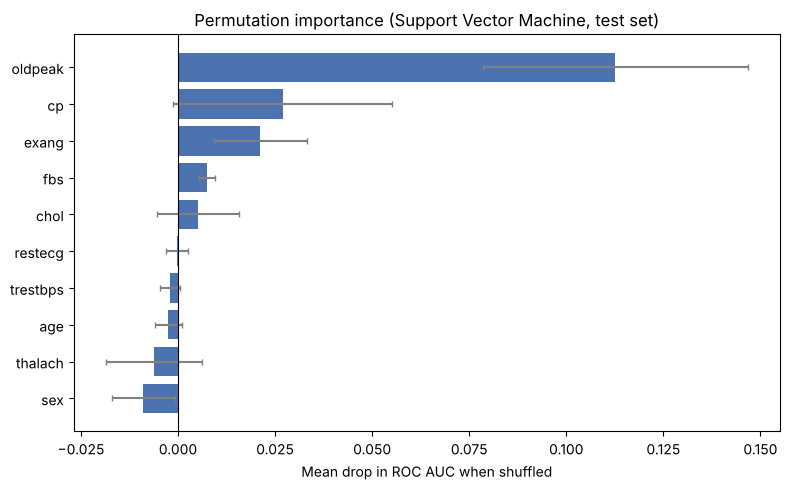

,Importance,Std,Rank
oldpeak,0.1126,0.0341,1
cp,0.0270,0.0283,2
exang,0.0212,0.0120,3
fbs,0.0075,0.0020,4
chol,0.0051,0.0105,5
restecg,-0.0002,0.0029,6
trestbps,-0.0021,0.0026,7
age,-0.0025,0.0035,8
thalach,-0.0062,0.0124,9
sex,-0.0090,0.0081,10


In [29]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=50, random_state=42, n_jobs=-1)
importances = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance_std = pd.Series(perm.importances_std, index=X_test.columns)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importances.index, importances.values, xerr=importance_std[importances.index], color="#4C72B0",
        ecolor="grey", capsize=2)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Mean drop in ROC AUC when shuffled")
ax.set_title(f"Permutation importance ({best_name}, test set)")
plt.tight_layout()
plt.show()

pd.DataFrame({"Importance": importances, "Std": importance_std[importances.index],
              "Rank": importances.rank(ascending=False).astype(int)}).sort_values("Rank").round(4)

### 3.6.1 Logistic Regression Coefficients

Permutation importance on 59 test patients is noisy, and it only shows *how much* a feature matters, not in which *direction*. As a complementary view, the tuned Logistic Regression is refitted on the training + validation data and its coefficients are converted to **odds ratios**. An odds ratio above 1 means the feature raises the odds of disease, and below 1 lowers them.

- For the standardised numerical features, the odds ratio is per one standard deviation.
- For binary features, it compares 1 with 0.
- For the one-hot categories, it compares each category with the average category.

Because all features are in the model together, each odds ratio describes the effect of that feature *while the others are held constant*. This makes it a multivariate check on the research questions.

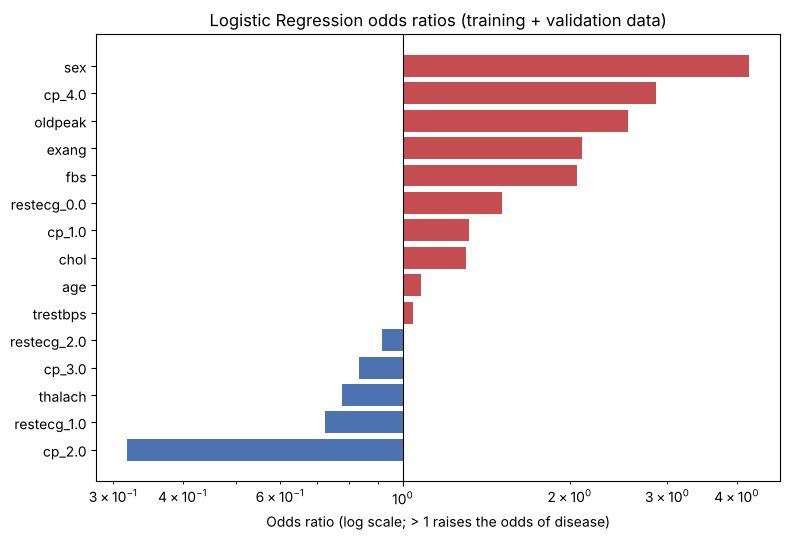

,Odds ratio
sex,4.21
cp_4.0,2.86
oldpeak,2.55
exang,2.10
fbs,2.06
restecg_0.0,1.51
cp_1.0,1.32
chol,1.30
age,1.08
trestbps,1.04


In [30]:
lr = clone(tuned["Logistic Regression"]).fit(X_trainval, y_trainval)
coef_names = [n.split("__")[1] for n in lr.named_steps["prep"].get_feature_names_out()]
odds = pd.Series(np.exp(lr.named_steps["clf"].coef_[0]), index=coef_names).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(odds.index, odds.values - 1, left=1, color=["#C44E52" if v > 1 else "#4C72B0" for v in odds.values])
ax.axvline(1, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel("Odds ratio (log scale; > 1 raises the odds of disease)")
ax.set_title("Logistic Regression odds ratios (training + validation data)")
plt.tight_layout()
plt.show()

odds.sort_values(ascending=False).rename("Odds ratio").round(2).to_frame()

## 3.7 Discussion

**Model comparison.** Cross-validated ROC AUC on the training set:

| Model | CV ROC AUC |
|---|---|
| Support Vector Machine | 0.896 |
| Random Forest (tuned) | 0.893 |
| Logistic Regression | 0.892 |
| K-Nearest Neighbours | 0.874 |
| Gradient Boosting | 0.866 |
| Gaussian Naive Bayes | 0.862 |
| Random Forest (default) | 0.862 |
| Decision Tree | 0.684 |
| Baseline | 0.500 |

The top three are separated by only 0.004, far less than their fold-to-fold standard deviation (about ±0.045), so they should be treated as **equally good**. The SVM was selected because it had the highest score, but Section 4.1.1 tests whether this lead is real.

**Simple models win on this dataset:**

- Every tuned model preferred its most heavily regularised settings:
  - the Random Forest chose shallow trees (`max_depth=3`) with at least 10 patients per leaf;
  - Gradient Boosting chose the fewest, shallowest trees (50 trees of depth 2);
  - the SVM chose a small `gamma` (0.01), which gives a smooth, almost linear boundary;
  - KNN chose a large neighbourhood (k = 31).
- Logistic Regression, a purely linear model, is within 0.004 of the best.
- Even Gaussian Naive Bayes (0.862) performs reasonably.

All of this points to the same conclusion: with 175 training patients and a signal that is largely linear (Section 2.4.3), there is little to gain from complex boundaries and a real risk of over-fitting. The unconstrained Decision Tree shows the risk clearly: it has by far the lowest CV score (0.684).

**Why cross-validation was used for selection.** The validation set (59 patients) gave a misleading ranking. The untuned Random Forest had the *highest* validation ROC AUC (0.920) despite a mediocre CV score. The Decision Tree reached 84.7% validation accuracy despite the worst CV score. With so few patients, one or two patients can reorder the models, whereas cross-validation averages over 25 different splits.

**Test performance.** Retrained on 234 patients, the SVM reached:

| Metric (test set) | Score |
|---|---|
| ROC AUC | 0.902 |
| Accuracy | 79.7% |
| Balanced accuracy | 0.778 |
| Sensitivity | 0.714 |
| Specificity | 0.842 |

The model correctly identified 15 of the 21 patients with heart disease and 32 of the 38 without, with 6 errors of each kind. The test ROC AUC matches the CV estimate (0.896), so the model generalises as expected. All tuned models scored between 0.888 and 0.902 ROC AUC on the test set (Section 3.5.1), which confirms that the choice of algorithm matters little here.

**At the default threshold, the model misses 29% of the disease cases.** For screening, that is too many. Section 4.2.2 addresses this by choosing a threshold that favours sensitivity.

**Feature importance and the research questions.**

- **Permutation importance** shows that the SVM relies most on `oldpeak` (ROC AUC drops by 0.113 when it is shuffled), followed by `cp` (0.027) and `exang` (0.021). The other features have importances close to zero, within their error bars. This is partly because the three strongest features are correlated (Section 2.3): when one is shuffled, the others still carry much of the same information.
- **The Logistic Regression odds ratios** (Section 3.6.1) give a clearer, multivariate picture and support every research question:

| Feature | Odds ratio | Research question |
|---|---|---|
| Male sex | 4.21 | RQ5 |
| Asymptomatic chest pain | 2.86 | RQ1 |
| `oldpeak` (per standard deviation) | 2.55 | RQ3 |
| Exercise-induced angina | 2.10 | RQ2 |
| `thalach` (per standard deviation) | 0.78 | RQ4 |
| `chol` (per standard deviation) | 1.30 | RQ6 |
| `trestbps` (per standard deviation) | 1.04 | RQ6 |

  Atypical angina lowers the odds (0.32). Higher maximum heart rate is protective, as RQ4 assumed. Cholesterol and resting blood pressure add little once the other features are included, as RQ6 assumed. High fasting blood sugar has an odds ratio of 2.06, but it is based on only 8 training patients.
- **Sex is the one disagreement between the two methods.** It is the strongest factor in the Logistic Regression, yet shows no permutation importance for the SVM. With only 59 test patients, of whom about a quarter are women, permutation importance for sex is very uncertain. The Logistic Regression estimate, based on 234 patients and adjusted for the other features, is the more reliable of the two, and it agrees with the stratified analysis in Section 2.4.2.

# 4 Model Evaluation & Further Modelling Improvements

Section 3 selected a model and reported its test-set scores. This section looks more closely at how good that model is, and then tests whether it can be improved.

- **4.1 Model Evaluation:**
  - whether the model ranking is stable across many data splits;
  - ROC and precision-recall curves;
  - a learning curve, to check for over- or under-fitting;
  - how confident the model is when it is right and when it is wrong.
- **4.2 Further Improvements:** feature selection, feature engineering and an ensemble, followed by choosing a decision threshold suited to screening. Every change is judged by repeated cross-validation on the training set and checked on the validation set. The test set is not used to choose between them.
- **4.3 Conclusion.**

## 4.1 Model Evaluation

### 4.1.1 Stability of the Model Ranking

To measure how much scores vary from one split to another, all five tuned models are compared on the combined training + validation data (234 patients) using 5-fold cross-validation repeated 10 times, which gives 50 scores per model. Every model sees exactly the same folds, so the scores can be compared fold by fold (paired).

Random Forest (tuned) minus Support Vector Machine, fold by fold: mean +0.000, std 0.019, Random Forest (tuned) better in 26 of 50 folds


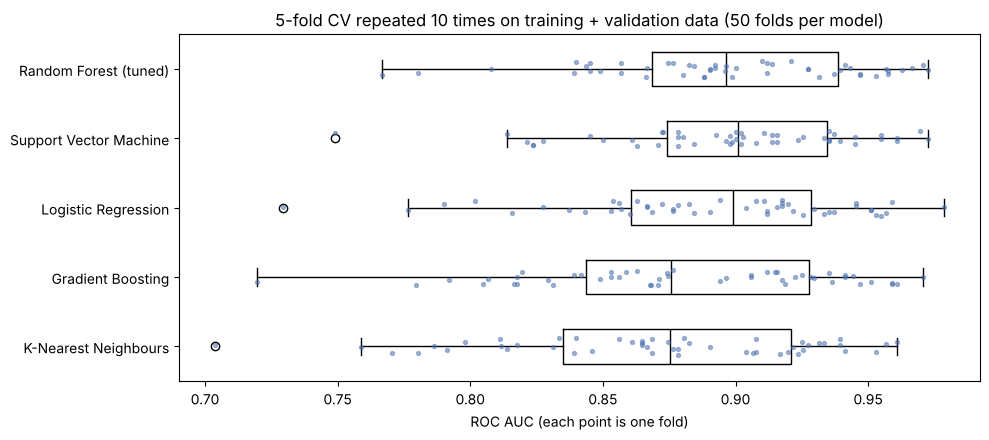

,Mean ROC AUC,Std,Min,Max
Random Forest (tuned),0.898,0.048,0.767,0.973
Support Vector Machine,0.898,0.046,0.749,0.973
Logistic Regression,0.891,0.052,0.729,0.978
Gradient Boosting,0.882,0.056,0.720,0.971
K-Nearest Neighbours,0.871,0.058,0.704,0.961


In [31]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=7)
fold_scores = pd.DataFrame({name: cross_val_score(clone(m), X_trainval, y_trainval, cv=rcv, scoring="roc_auc", n_jobs=-1)
                            for name, m in tuned.items()})
order_models = fold_scores.mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([fold_scores[c] for c in order_models], vert=False, widths=0.5, medianprops={"color": "black"})
for i, c in enumerate(order_models, start=1):
    ax.scatter(fold_scores[c], np.full(len(fold_scores), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(fold_scores)),
               color="#4C72B0", s=8, alpha=0.5, zorder=3)
ax.set_yticks(range(1, len(order_models) + 1))
ax.set_yticklabels(order_models)
ax.invert_yaxis()
ax.set_xlabel("ROC AUC (each point is one fold)")
ax.set_title("5-fold CV repeated 10 times on training + validation data (50 folds per model)")
plt.tight_layout()
plt.show()

first, second = order_models[0], order_models[1]
diff = fold_scores[first] - fold_scores[second]
print(f"{first} minus {second}, fold by fold: mean {diff.mean():+.3f}, std {diff.std():.3f}, "
      f"{first} better in {(diff > 0).sum()} of {len(diff)} folds")
pd.DataFrame({"Mean ROC AUC": fold_scores.mean(), "Std": fold_scores.std(),
              "Min": fold_scores.min(), "Max": fold_scores.max()}).loc[order_models].round(3)

### 4.1.2 ROC and Precision-Recall Curves

The ROC curve shows the trade-off between sensitivity (true positive rate) and 1 − specificity (false positive rate) across every possible threshold. The precision-recall curve shows, for each level of sensitivity (recall), what share of the patients flagged as diseased actually have the disease (precision). Its baseline is the disease rate in the test set (dashed line). Curves are drawn for every tuned model on the test set, with the selected model in bold.

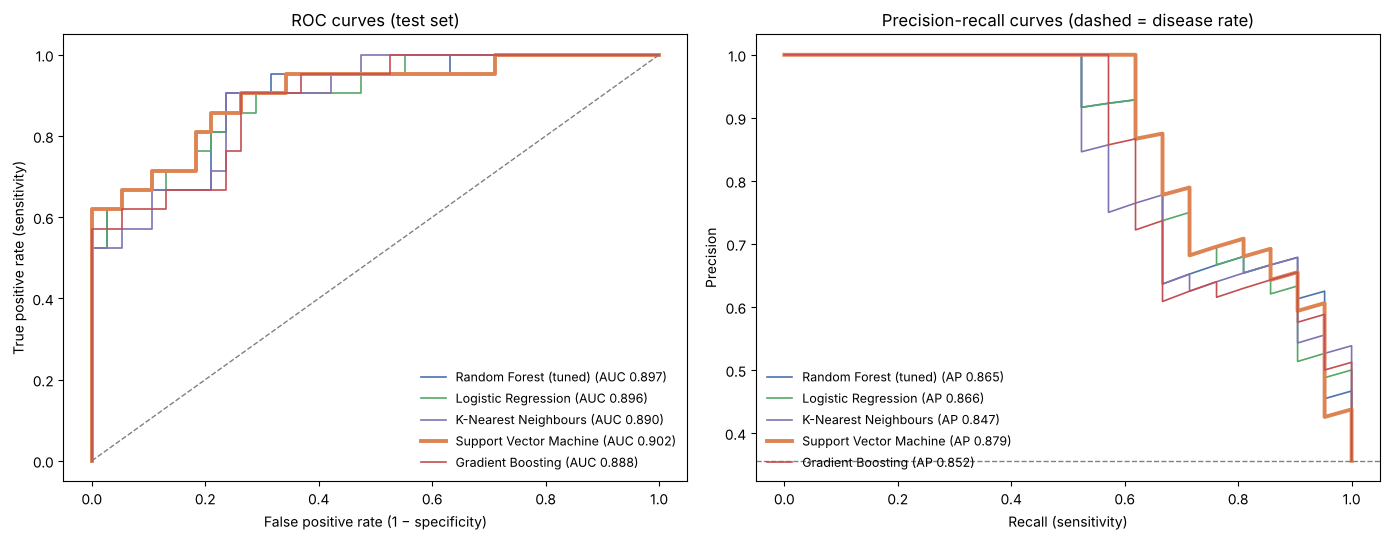

,ROC AUC,Average precision
Random Forest (tuned),0.897,0.865
Logistic Regression,0.896,0.866
K-Nearest Neighbours,0.890,0.847
Support Vector Machine,0.902,0.879
Gradient Boosting,0.888,0.852


In [32]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

model_colours = dict(zip(tuned, ["#4C72B0", "#55A868", "#8172B3", "#DD8452", "#C44E52"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
curve_rows = {}
for name, m in tuned.items():
    fitted = final_model if name == best_name else clone(m).fit(X_trainval, y_trainval)
    p = fitted.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    auc, ap = roc_auc_score(y_test, p), average_precision_score(y_test, p)
    curve_rows[name] = {"ROC AUC": auc, "Average precision": ap}
    lw = 2.8 if name == best_name else 1.2
    axes[0].plot(fpr, tpr, color=model_colours[name], linewidth=lw, label=f"{name} (AUC {auc:.3f})")
    axes[1].plot(rec, prec, color=model_colours[name], linewidth=lw, label=f"{name} (AP {ap:.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
axes[0].set_xlabel("False positive rate (1 − specificity)")
axes[0].set_ylabel("True positive rate (sensitivity)")
axes[0].set_title("ROC curves (test set)")
axes[1].axhline(y_test.mean(), color="grey", linestyle="--", linewidth=1)
axes[1].set_xlabel("Recall (sensitivity)")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves (dashed = disease rate)")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

pd.DataFrame(curve_rows).T.round(3)

### 4.1.3 Learning Curve

A learning curve trains the model on increasing amounts of data and compares the score on the data it was trained on with the score on held-out folds.

- A **large gap** between the two lines indicates over-fitting.
- **Both lines low** indicates under-fitting.
- A **validation line still rising** at the right-hand end suggests more data would help.

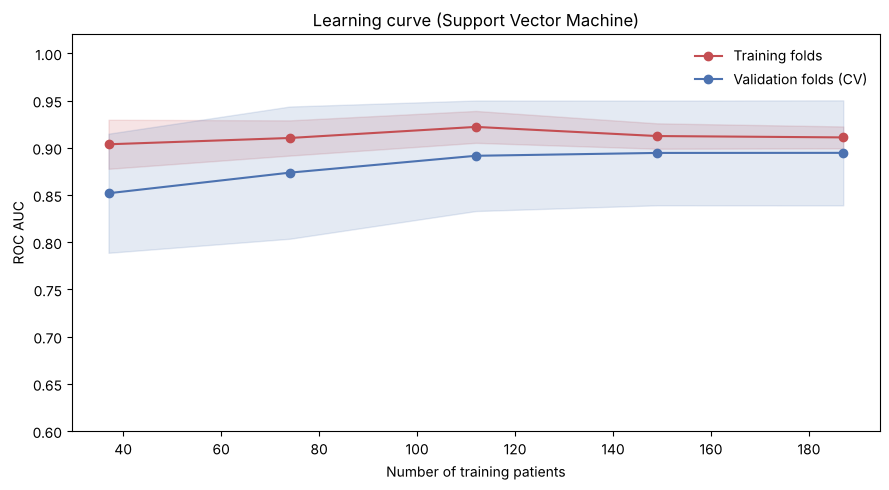

,Training patients,Train ROC AUC,CV ROC AUC,CV std
0,37,0.904,0.852,0.063
1,74,0.910,0.874,0.070
2,112,0.922,0.892,0.059
3,149,0.912,0.895,0.055
4,187,0.911,0.895,0.056


In [33]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(clone(final_model), X_trainval, y_trainval,
                                         cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42),
                                         scoring="roc_auc", train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1)

fig, ax = plt.subplots(figsize=(9, 5))
for sc, label, col in [(train_sc, "Training folds", "#C44E52"), (val_sc, "Validation folds (CV)", "#4C72B0")]:
    ax.plot(sizes, sc.mean(axis=1), marker="o", color=col, label=label)
    ax.fill_between(sizes, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=col, alpha=0.15)
ax.set_xlabel("Number of training patients")
ax.set_ylabel("ROC AUC")
ax.set_ylim(0.6, 1.02)
ax.set_title(f"Learning curve ({best_name})")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

pd.DataFrame({"Training patients": sizes, "Train ROC AUC": train_sc.mean(axis=1).round(3),
              "CV ROC AUC": val_sc.mean(axis=1).round(3), "CV std": val_sc.std(axis=1).round(3)})

### 4.1.4 Prediction Confidence

The chart shows the predicted probability of disease for every test patient, split by their true class. A good model pushes healthy patients towards 0 and diseased patients towards 1, with little overlap. The table shows accuracy within bands of confidence, where confidence is how far the probability is from 0.5. If accuracy rises with confidence, the probabilities can be used to flag uncertain patients for closer attention.

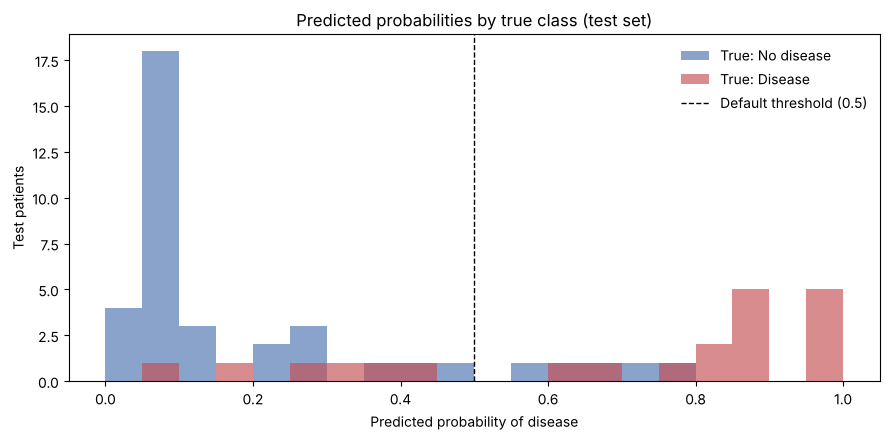

,Patients,Accuracy
Low (p 0.3–0.7),11,0.455
Medium,12,0.667
High (p < 0.15 or > 0.85),36,0.972


In [34]:
proba = final_model.predict_proba(X_test)[:, 1]
correct = ((proba >= 0.5).astype(int) == y_test.values)  # judged on the probabilities shown in the chart

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(0, 1, 21)
for k in (0, 1):
    ax.hist(proba[(y_test == k).values], bins=bins, alpha=0.65, color=colours[k], label=f"True: {labels[k]}")
ax.axvline(0.5, color="black", linestyle="--", linewidth=1, label="Default threshold (0.5)")
ax.set_xlabel("Predicted probability of disease")
ax.set_ylabel("Test patients")
ax.set_title("Predicted probabilities by true class (test set)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

confidence = np.abs(proba - 0.5) * 2
band = pd.cut(confidence, [0, 0.4, 0.7, 1.0], include_lowest=True, labels=["Low (p 0.3–0.7)", "Medium", "High (p < 0.15 or > 0.85)"])
pd.DataFrame({"Patients": pd.Series(band).value_counts().sort_index(),
              "Accuracy": pd.Series(correct).groupby(band, observed=False).mean().round(3).values})

## 4.2 Further Modelling Improvements

Each improvement is applied to the selected model and its tuned settings, so that any change in score comes from the improvement itself. Each version is scored with the same repeated 5-fold cross-validation on the training set (25 folds) and checked once on the validation set.

A change is only treated as a real improvement if it beats the baseline by clearly more than the fold-to-fold noise on **both** measures. The relevant noise is the standard error of the mean over 25 folds, roughly the fold standard deviation divided by 5.

### 4.2.1 Feature Changes and Ensemble

| Experiment | Idea | Motivation |
|---|---|---|
| Remove `restecg` | Drop the resting ECG | Section 2.3: no relationship with the target (Cramér's V = 0.10) |
| Remove resting risk factors | Drop `restecg`, `trestbps`, `fbs` and `chol` | RQ6: test whether the model needs anything beyond demographics, chest pain and the exercise test |
| Feature engineering | Add physiologically motivated features (below) | Gives the model relationships that clinicians use directly |
| Soft-voting ensemble | Average the probabilities of the three best tuned models | The top models were close in Section 4.1.1; averaging can reduce errors that only one of them makes |

**Engineered features:**

- **`hr_percent_max`:** `thalach` as a share of the age-predicted maximum heart rate (220 − age). The scatter plot in Section 2.4.1 showed that a low maximum heart rate *for one's age* is more telling than a low heart rate on its own.
- **`st_depression`:** 1 if `oldpeak` > 0, otherwise 0. Most patients have no ST depression at all (Section 2.2), so the presence or absence of any depression may be more informative than its exact size.
- **`chol_missing`:** 1 if cholesterol was not recorded. Section 2.1.1 showed that the disease rate differs when `chol` is missing, so the missingness itself may carry information.

These features are calculated row by row from each patient's own values, so adding them does not leak any information between patients.

In [35]:
def add_features(df):
    df = df.copy()
    df["hr_percent_max"] = df["thalach"] / (220 - df["age"])
    df["st_depression"] = (df["oldpeak"] > 0).astype(int)
    df["chol_missing"] = df["chol"].isna().astype(int)
    return df

base_clf = clone(final_model.named_steps["clf"])
engineered = ["hr_percent_max", "st_depression", "chol_missing"]

feature_sets = {
    "Baseline (all 10 features)": (lambda d: d, ()),
    "Remove restecg": (lambda d: d.drop(columns=["restecg"]), ()),
    "Remove resting risk factors": (lambda d: d.drop(columns=["restecg", "trestbps", "fbs", "chol"]), ()),
    "Feature engineering": (add_features, engineered),
}

experiments = {}
for name, (transform, extra) in feature_sets.items():
    Xa, Xb = transform(X_train), transform(X_val)
    model = make_model(clone(base_clf), Xa.columns, extra)
    scores = cross_val_score(model, Xa, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    val_auc = roc_auc_score(y_val, model.fit(Xa, y_train).predict_proba(Xb)[:, 1])
    experiments[name] = {"Features": Xa.shape[1], "CV ROC AUC": scores.mean(), "CV std": scores.std(), "Validation ROC AUC": val_auc}
    print(f"{name:30s} CV {scores.mean():.3f} ± {scores.std():.3f}   validation {val_auc:.3f}")

Baseline (all 10 features)     CV 0.896 ± 0.046   validation 0.886
Remove restecg                 CV 0.896 ± 0.046   validation 0.887
Remove resting risk factors    CV 0.888 ± 0.042   validation 0.910
Feature engineering            CV 0.891 ± 0.045   validation 0.878


In [36]:
from sklearn.ensemble import VotingClassifier

top3 = comparison.loc[list(tuned), "CV ROC AUC (train)"].sort_values(ascending=False).index[:3]
print("Ensemble members:", ", ".join(top3))
voting = VotingClassifier([(f"m{i}", clone(tuned[n])) for i, n in enumerate(top3)], voting="soft")
scores = cross_val_score(voting, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
val_auc = roc_auc_score(y_val, clone(voting).fit(X_train, y_train).predict_proba(X_val)[:, 1])
experiments["Soft-voting ensemble (top 3)"] = {"Features": X_train.shape[1], "CV ROC AUC": scores.mean(),
                                                "CV std": scores.std(), "Validation ROC AUC": val_auc}
print(f"Soft-voting ensemble (top 3)   CV {scores.mean():.3f} ± {scores.std():.3f}   validation {val_auc:.3f}")

Ensemble members: Support Vector Machine, Random Forest (tuned), Logistic Regression
Soft-voting ensemble (top 3)   CV 0.898 ± 0.041   validation 0.902


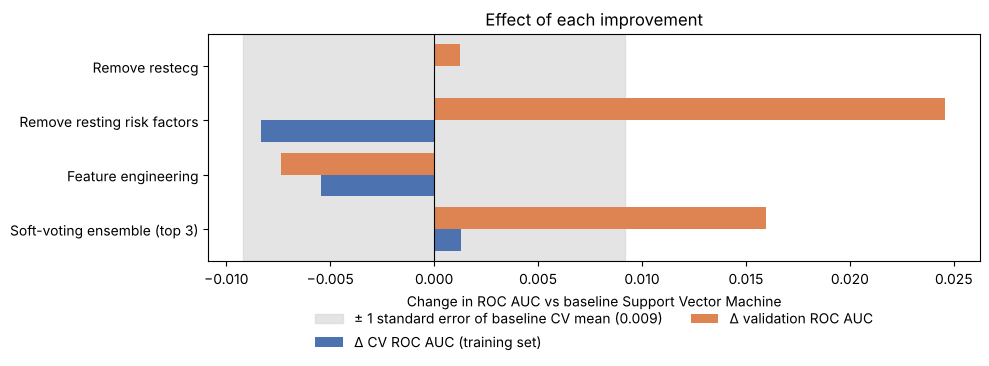

,Features,CV ROC AUC,CV std,Validation ROC AUC,Δ CV,Δ validation
Baseline (all 10 features),10,0.896,0.046,0.886,+0.000,+0.000
Remove restecg,9,0.896,0.046,0.887,-0.000,+0.001
Remove resting risk factors,6,0.888,0.042,0.910,-0.008,+0.025
Feature engineering,13,0.891,0.045,0.878,-0.005,-0.007
Soft-voting ensemble (top 3),10,0.898,0.041,0.902,+0.001,+0.016


In [37]:
exp = pd.DataFrame(experiments).T
base_row = exp.loc["Baseline (all 10 features)"]
exp["Δ CV"] = exp["CV ROC AUC"] - base_row["CV ROC AUC"]
exp["Δ validation"] = exp["Validation ROC AUC"] - base_row["Validation ROC AUC"]
noise = base_row["CV std"] / np.sqrt(25)

plot = exp.drop(index="Baseline (all 10 features)").iloc[::-1]
y_pos = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axvspan(-noise, noise, color="lightgrey", alpha=0.6, label=f"± 1 standard error of baseline CV mean ({noise:.3f})")
ax.barh(y_pos - 0.2, plot["Δ CV"], height=0.4, color="#4C72B0", label="Δ CV ROC AUC (training set)")
ax.barh(y_pos + 0.2, plot["Δ validation"], height=0.4, color="#DD8452", label="Δ validation ROC AUC")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot.index)
ax.set_xlabel(f"Change in ROC AUC vs baseline {best_name}")
ax.set_title("Effect of each improvement")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.45), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

exp.style.format({"Features": "{:.0f}", "CV ROC AUC": "{:.3f}", "CV std": "{:.3f}", "Validation ROC AUC": "{:.3f}",
                  "Δ CV": "{:+.3f}", "Δ validation": "{:+.3f}"})

### 4.2.2 Choosing a Decision Threshold for Screening

By default, a patient is predicted to have heart disease if the model's probability is above 0.5. For a screening tool, missing a diseased patient is worse than sending a healthy one for further tests, so a lower threshold that catches more of the disease cases may be preferable.

One technical point: for the SVM, `predict()` uses the model's internal decision function, while `predict_proba()` uses probabilities calibrated separately (Platt scaling). The two can disagree for a few patients near the boundary. In this section, all predictions are made by thresholding the probabilities, so the "Default (0.50)" row below can differ slightly from Section 3.5.

The threshold is chosen on **out-of-fold** probabilities from cross-validation on the combined training + validation data, i.e. predictions for patients the model was not trained on. The aim is the highest threshold that still gives **at least 90% sensitivity**. The chosen threshold is then applied to the test set, which played no part in choosing it.

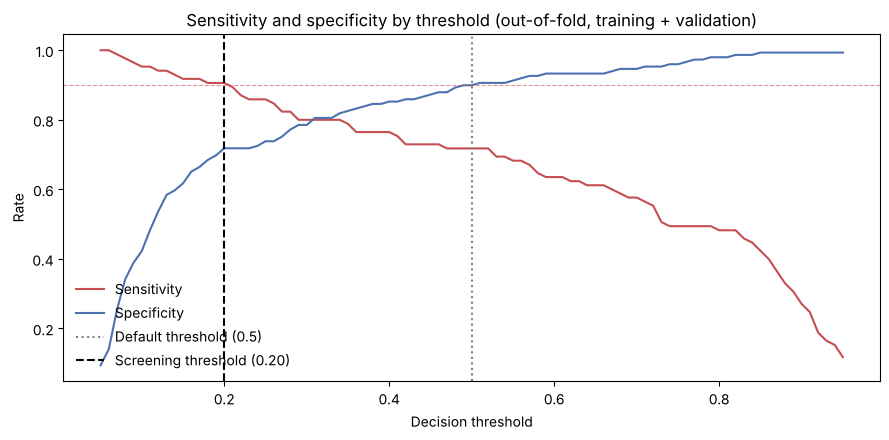

,OOF sensitivity,OOF specificity,Test sensitivity,Test specificity,Test accuracy,Test missed disease cases,Test false alarms
Default (0.50),0.718,0.899,0.714,0.868,0.814,6.000000,5.000000
Screening (0.20),0.906,0.718,0.905,0.658,0.746,2.000000,13.000000


In [38]:
from sklearn.model_selection import cross_val_predict

oof = np.zeros(len(y_trainval))
for r in range(5):
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + r)
    oof += cross_val_predict(clone(final_model), X_trainval, y_trainval, cv=folds, method="predict_proba", n_jobs=-1)[:, 1] / 5

thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
sens = np.array([recall_score(y_trainval, (oof >= t).astype(int)) for t in thresholds])
spec = np.array([recall_score(y_trainval, (oof >= t).astype(int), pos_label=0) for t in thresholds])
screen_t = thresholds[sens >= 0.90].max()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thresholds, sens, color="#C44E52", label="Sensitivity")
ax.plot(thresholds, spec, color="#4C72B0", label="Specificity")
ax.axvline(0.5, color="grey", linestyle=":", label="Default threshold (0.5)")
ax.axvline(screen_t, color="black", linestyle="--", label=f"Screening threshold ({screen_t:.2f})")
ax.axhline(0.9, color="#C44E52", linestyle="--", linewidth=0.8, alpha=0.6)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Rate")
ax.set_title("Sensitivity and specificity by threshold (out-of-fold, training + validation)")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

rows = {}
for label, t in [("Default (0.50)", 0.5), (f"Screening ({screen_t:.2f})", screen_t)]:
    pred_oof, pred_test = (oof >= t).astype(int), (proba >= t).astype(int)
    rows[label] = {
        "OOF sensitivity": recall_score(y_trainval, pred_oof), "OOF specificity": recall_score(y_trainval, pred_oof, pos_label=0),
        "Test sensitivity": recall_score(y_test, pred_test), "Test specificity": recall_score(y_test, pred_test, pos_label=0),
        "Test accuracy": accuracy_score(y_test, pred_test),
        "Test missed disease cases": int(((pred_test == 0) & (y_test.values == 1)).sum()),
        "Test false alarms": int(((pred_test == 1) & (y_test.values == 0)).sum()),
    }
pd.DataFrame(rows).T.style.format({c: "{:.3f}" for c in ["OOF sensitivity", "OOF specificity", "Test sensitivity",
                                                           "Test specificity", "Test accuracy"]})

## 4.3 Conclusion

**Model evaluation**

- **Ranking stability (4.1.1).** Over 50 repeated CV folds on the training and validation data, the tuned Random Forest and the SVM are exactly tied (mean ROC AUC 0.898 each). The Random Forest wins 26 of the 50 paired folds, with a mean difference of 0.000. Logistic Regression (0.891), Gradient Boosting (0.882) and KNN (0.871) follow. The SVM's narrow lead in Section 3.4 was chance, but so is any other ordering of the top three. The SVM is kept as the final model because it was chosen by the planned procedure, and it performs as well as any alternative.
- **ROC and precision-recall curves (4.1.2).** On the test set, the SVM has a ROC AUC of 0.902 and an average precision of 0.879, against a baseline of 0.356 for a random model. The curves of all five tuned models lie close together.
- **Learning curve (4.1.3).** Training ROC AUC stays around 0.91, while CV ROC AUC rises from 0.852 (37 patients) to 0.895 (149 patients) and then levels off. The small gap between the two lines (about 0.016 at full size) shows the model is **not over-fitting**. The flat right-hand end suggests that more patients alone would bring only modest gains for this model. Further progress is more likely to come from **better features**, such as the three attributes that had to be removed (`ca`, `thal`, `slope`), which are known to be strong predictors when they are recorded.
- **Confidence (4.1.4).** For 36 of the 59 test patients, the model's predicted probability is below 0.15 or above 0.85, and it is right for 97% of these. For the 11 patients with probabilities between 0.3 and 0.7, it is right for only 45%. In practice, the model can confidently sort about 60% of patients, while the uncertain middle group could be referred for further tests regardless.

**Further improvements (4.2.1)**

None of the changes improved the model by more than the noise level (± 0.009, one standard error of the baseline CV mean):

| Change | Δ CV ROC AUC | Δ validation ROC AUC |
|---|---|---|
| Remove `restecg` | 0.000 | +0.001 |
| Remove all resting risk factors (6 features left) | −0.008 | +0.025 |
| Add engineered features | −0.005 | −0.007 |
| Soft-voting ensemble (SVM + Random Forest + Logistic Regression) | +0.001 | +0.016 |

The resting ECG contributes nothing and can be removed. A model using only six features (age, sex, chest pain type, maximum heart rate, exercise angina and ST depression) performs essentially as well as the full model. This supports RQ6 and suggests a simpler model would be just as useful. The engineered features did not help, as the SVM can already combine age and heart rate itself. The ensemble produced the best validation score, but its CV gain is negligible. **The Section 3 model is therefore kept unchanged.**

**Decision threshold (4.2.2)**

This is the most practically useful result of the section. Lowering the threshold from 0.5 to **0.20**, chosen on out-of-fold predictions only, raises sensitivity on the test set from 0.714 to **0.905**:

| Threshold | Missed disease cases | Healthy patients flagged | Specificity |
|---|---|---|---|
| 0.5 (default) | 6 of 21 | 5 of 38 | 0.868 |
| 0.20 (screening) | 2 of 21 | 13 of 38 | 0.658 |

The test sensitivity (0.905) matches the out-of-fold target (0.906), so the threshold transfers reliably to new patients. Whether this trade-off is worthwhile is a clinical decision. For a screening tool that decides who is referred for angiography, missing fewer patients with disease would usually justify the extra referrals.

# 5 Summary & Conclusion

## 5.1 Summary

This notebook set out to predict whether a patient has coronary heart disease, defined as more than 50% narrowing of a major coronary artery on angiography, using routine, non-invasive clinical measurements from the Hungarian subset of the UCI Heart Disease database.

**Data preparation.** The dataset contained 294 patients and 14 attributes, with missing values recorded as `?`:

- Three attributes were missing for most patients and were removed: `ca` (99%), `thal` (90.5%) and `slope` (64.6%). `slope` was shown to be recorded almost only when ST depression was present, so its information is largely captured by `oldpeak`.
- One duplicate row was removed.
- The remaining gaps (mainly 7.8% of `chol`) were filled with training-set medians or most frequent values inside the modelling pipeline.
- The 293 remaining patients were split 60/20/20 into stratified training, validation and test sets.

**Exploratory data analysis.**

- **Univariate:** the sample is 73% male with a median age of 48. `oldpeak` is heavily skewed, as 63% of patients show no ST depression.
- **Bivariate:** chest pain type, exercise-induced angina and ST depression have large effects on the disease rate. Maximum heart rate and sex have medium effects. The resting measurements (cholesterol, blood pressure, fasting blood sugar, resting ECG) have small or no effects.
- **Multivariate:** combinations of chest pain type, exercise angina and sex split patients into groups with disease rates from 6% to 92%. The sex difference remains within each chest pain group. The classes separate fairly well along the first principal component, and multicollinearity is low (all VIF < 2.1).

**Modelling.** Nine models were compared:

- a baseline;
- Gaussian Naive Bayes;
- a Decision Tree;
- a Random Forest;
- Logistic Regression;
- K-Nearest Neighbours;
- a Support Vector Machine;
- Gradient Boosting.

The Random Forest appears twice, with default and tuned settings. Preprocessing ran inside a pipeline, tuning used repeated stratified 5-fold cross-validation, and models were compared on ROC AUC. The SVM, the tuned Random Forest and Logistic Regression performed best and were statistically indistinguishable. Every model preferred heavily regularised settings. The SVM was selected and evaluated once on the test set.

**Further improvements.** Removing features, adding engineered features and ensembling all changed performance by less than the noise level. Lowering the decision threshold to 0.20 raised sensitivity to about 90% at the cost of specificity.

## 5.2 Final Results

| Model (test set, 59 patients) | ROC AUC | Accuracy | Balanced accuracy | Sensitivity | Specificity |
|---|---|---|---|---|---|
| Baseline (always predicts no disease) | 0.500 | 0.644 | 0.500 | 0.000 | 1.000 |
| SVM, default threshold | **0.902** | **0.797** | 0.778 | 0.714 | 0.842 |
| SVM, screening threshold (0.20) | 0.902 | 0.746 | 0.781 | **0.905** | 0.658 |

The test ROC AUC (0.902) closely matches the cross-validated estimate (0.896), so the reported performance is a reliable guide to how the model would perform on similar new patients.

## 5.3 Research Questions

| ID | Question | Conclusion | Evidence |
|---|---|---|---|
| RQ1 | Does chest pain type relate to heart disease? | **Supported** | Asymptomatic patients: 68% disease rate against 8–25% for other pain types (Cramér's V = 0.58). Odds ratio 2.86. Second most important feature for the SVM. |
| RQ2 | Does exercise-induced angina relate to heart disease? | **Supported** | 78% vs 19% disease rate (V = 0.54). Odds ratio 2.10. Third most important feature. |
| RQ3 | Is ST depression larger with heart disease? | **Supported** | Median 1.5 vs 0 mm (r = +0.57). Odds ratio 2.55 per SD. By far the most important feature for the SVM. |
| RQ4 | Is maximum heart rate lower with heart disease? | **Supported** | Median 130 vs 142 bpm (r = −0.36). The difference remains relative to age-predicted maximum (74% vs 83%). Odds ratio 0.78 per SD. |
| RQ5 | Do men have a higher rate of heart disease? | **Supported** | 44% vs 15%, and higher within each chest pain group. Strongest odds ratio (4.21), although permutation importance on the small test set was inconclusive. |
| RQ6 | Do resting risk factors separate the classes less clearly? | **Supported** | Small or no effects in the EDA. Odds ratios close to 1. A model without them performs as well as the full model. |

## 5.4 Limitations

- **Small sample.** With 293 patients, and only 59 in each of the validation and test sets, every estimate carries considerable uncertainty. Repeated cross-validation was used to reduce this, but small differences between models (a few hundredths of ROC AUC) cannot be resolved.
- **Strong predictors had to be removed.** `ca`, `thal` and `slope` are among the most informative attributes in the related Cleveland dataset, but they are almost entirely missing here. The models are therefore limited to the remaining, weaker set of features.
- **Single hospital and an unrepresentative sample.** All patients were referred for angiography in one Hungarian hospital in the 1980s. They are not a random sample of the general population: they were already suspected of heart disease, and 73% are men. Results may not transfer to other populations or to modern patients.
- **Small subgroups.** Only 8 training patients have high fasting blood sugar, only 4 have typical angina and only 3 show left ventricular hypertrophy. Conclusions about these groups are unreliable.
- **Missing values were filled with simple single values** (median or most frequent). This ignores the uncertainty in the filled values, and Section 2.1.1 showed that missingness in `chol` is related to the target.
- **A decision threshold is not a clinical decision.** The 0.20 threshold was chosen to meet a 90% sensitivity target set for illustration. A real threshold would need to be agreed with clinicians, based on the costs and risks of angiography.

## 5.5 Future Work

- **Use more data.** Combine the Hungarian data with the Cleveland, Swiss and Long Beach subsets of the same database. This would roughly triple the sample, and the location could be included as a feature or used to test how well the model transfers between hospitals.
- **Handle missing values more fully.** Use multiple imputation or models that handle missing values natively, so that partially recorded attributes such as `slope` can be kept rather than removed.
- **Calibrate and validate.** Calibrate the predicted probabilities and validate the screening threshold on an external dataset before any clinical use.
- **Build a simpler model.** Develop a transparent model, such as Logistic Regression on the six strongest features. It performs almost identically, and clinicians can inspect it directly.

## 5.6 Conclusion

Routine, non-invasive measurements can predict the result of coronary angiography with good accuracy: the selected SVM reached a test ROC AUC of 0.902 and an accuracy of 79.7%. The most informative measurements come from the exercise stress test (ST depression and exercise-induced angina), together with chest pain type and sex. All six research questions were supported. The traditional resting risk factors, cholesterol and blood pressure, added little once these were known.

On this small dataset, the choice of algorithm mattered far less than it might appear. The SVM, Random Forest and Logistic Regression performed identically within the noise, and all models preferred their simplest settings. The most effective way to make the model useful in practice was not a more complex algorithm but a **lower decision threshold**. At 0.20, the model identified about 90% of patients with heart disease in the test set, missing 2 of 21 rather than 6. This makes it a plausible first-stage screening tool for deciding who should be referred for angiography, although it would need validation on modern and more varied patient groups before any clinical use.

## References

Detrano, R., Janosi, A., Steinbrunn, W., Pfisterer, M., Schmid, J., Sandhu, S., Guppy, K., Lee, S. and Froelicher, V. (1989) 'International application of a new probability algorithm for the diagnosis of coronary artery disease', *American Journal of Cardiology*, 64(5), pp. 304–310.

Janosi, A., Steinbrunn, W., Pfisterer, M. and Detrano, R. (1988) *Heart Disease* [Dataset]. UCI Machine Learning Repository. doi:10.24432/C52P4X.